In [54]:
# ============================================================
# CELL 1 — INSTALL, IMPORT, LOAD, AND BUILD FACEBOOK BENCHMARK
# ============================================================

# ------------------------------------------------------------
# 0. Install required packages
# ------------------------------------------------------------

!pip uninstall -y community -q

!pip install -q \
    numpy \
    pandas \
    networkx \
    scikit-learn \
    tqdm \
    python-louvain \
    GraphRicciCurvature \
    scipy \
    igraph \
    leidenalg \
    jinja2


# ------------------------------------------------------------
# 1. Imports and configuration
# ------------------------------------------------------------

import random
import tarfile
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import networkx as nx
from tqdm import tqdm

%load_ext autoreload
%autoreload 2

import community_detection_utils as cdu


RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

DATASET_NAME = "Facebook"


# ------------------------------------------------------------
# 2. Data paths and URLs
# ------------------------------------------------------------

DATA_DIR = Path("./data/facebook")

DATA_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

COMBINED_FILE = (
    DATA_DIR
    / "facebook_combined.txt.gz"
)

TAR_FILE = (
    DATA_DIR
    / "facebook.tar.gz"
)

EXTRACT_DIR = (
    DATA_DIR
    / "facebook"
)

COMBINED_URL = (
    "https://snap.stanford.edu/data/"
    "facebook_combined.txt.gz"
)

TAR_URL = (
    "https://snap.stanford.edu/data/"
    "facebook.tar.gz"
)


# ------------------------------------------------------------
# 3. Benchmark-selection settings
# ------------------------------------------------------------

MIN_CIRCLE_SIZE = 10
N_RANDOM_CIRCLES = 50


# ------------------------------------------------------------
# 4. Curvature settings
# ------------------------------------------------------------

# Connected-component selection settings
MIN_COMPONENT_NODES = 80
MAX_COMPONENT_NODES = 500

MIN_LABELS = 4
MAX_LABELS = 25
LRC_ONLY_PCT = 5
ORC_ONLY_PCT = 5

LRC_COMBO_PCT = 2.5
ORC_COMBO_PCT = 2.5

ALPHA = 0.5
ORC_ITERATIONS = 5

SEEDS = [
    0,
    1,
    2,
    3,
    4,
    42,
]


# ------------------------------------------------------------
# 5. Download and extract Facebook data
# ------------------------------------------------------------

cdu.download_if_missing(
    COMBINED_URL,
    COMBINED_FILE,
)

cdu.download_if_missing(
    TAR_URL,
    TAR_FILE,
)


if not EXTRACT_DIR.exists():

    print(
        "Extracting facebook.tar.gz..."
    )

    with tarfile.open(
        TAR_FILE,
        "r:gz",
    ) as tar:

        tar.extractall(
            DATA_DIR
        )

    print(
        "Extraction completed."
    )

else:

    print(
        "Facebook files already extracted."
    )


# ------------------------------------------------------------
# 6. Load Facebook graph and circles
# ------------------------------------------------------------

G_full = cdu.load_facebook_combined(
    COMBINED_FILE
)

communities = cdu.load_all_facebook_circles(
    EXTRACT_DIR,
    min_size=1,
)


print(
    G_full
)

print(
    "Total circles:",
    len(communities),
)

print(
    "Connected components:",
    nx.number_connected_components(
        G_full
    ),
)

print(
    "Largest component size:",
    len(
        max(
            nx.connected_components(
                G_full
            ),
            key=len,
        )
    ),
)

print(
    "\nCircle-size distribution:"
)

display(
    pd.Series(
        [
            community["size"]
            for community in communities
        ]
    ).describe()
)


# ------------------------------------------------------------
# 7. Compute structural metrics for eligible circles
# ------------------------------------------------------------

rows = []

for cid, community in tqdm(
    list(
        enumerate(
            communities
        )
    ),
    desc="Computing Facebook circle metrics",
):

    if (
        community["size"]
        < MIN_CIRCLE_SIZE
    ):
        continue

    metrics = (
        cdu.compute_community_metrics(
            G_full,
            community["nodes"],
        )
    )

    if metrics is not None:

        metrics[
            "community_id"
        ] = cid

        metrics[
            "ego_id"
        ] = community[
            "ego_id"
        ]

        metrics[
            "circle_name"
        ] = community[
            "circle_name"
        ]

        rows.append(
            metrics
        )


metric_df = pd.DataFrame(
    rows
)

metric_df = metric_df[
    np.isfinite(
        metric_df[
            "conductance"
        ]
    )
].copy()


print(
    "Eligible circles:",
    len(metric_df),
)

display(
    metric_df.describe()
)


# ------------------------------------------------------------
# 8. Reproducibly sample circles
# ------------------------------------------------------------

if len(metric_df) == 0:

    raise ValueError(
        "No eligible circles were found. "
        "Reduce MIN_CIRCLE_SIZE."
    )


rng = np.random.default_rng(
    RANDOM_SEED
)

number_to_select = min(
    N_RANDOM_CIRCLES,
    len(metric_df),
)

picked_ids = rng.choice(
    metric_df[
        "community_id"
    ].tolist(),
    size=number_to_select,
    replace=False,
).tolist()

picked_ids = sorted(
    picked_ids
)


selected_df = metric_df[
    metric_df[
        "community_id"
    ].isin(
        picked_ids
    )
].copy()


print(
    "Randomly selected circles:",
    len(selected_df),
)

display(
    selected_df[
        [
            "community_id",
            "ego_id",
            "circle_name",
            "size",
            "conductance",
            "BTD",
            "internal_edges",
            "boundary_edges",
        ]
    ]
)


# ------------------------------------------------------------
# 9. Build the raw benchmark graph
# ------------------------------------------------------------

node_to_cids = defaultdict(
    list
)

for cid in picked_ids:

    for node in communities[
        cid
    ][
        "nodes"
    ]:

        if node in G_full:

            node_to_cids[
                node
            ].append(
                cid
            )


nodes_of_interest = set(
    node_to_cids.keys()
)

G_raw = G_full.subgraph(
    nodes_of_interest
).copy()


print(
    f"Before GCC: "
    f"|V|={G_raw.number_of_nodes():,}, "
    f"|E|={G_raw.number_of_edges():,}"
)

print(
    "Components before GCC:",
    (
        nx.number_connected_components(
            G_raw
        )
        if G_raw.number_of_nodes() > 0
        else 0
    ),
)


# ------------------------------------------------------------
# ------------------------------------------------------------
# ------------------------------------------------------------
# 10. Retain the Giant Connected Component
# ------------------------------------------------------------

print(
    f"Before GCC: "
    f"|V|={G_raw.number_of_nodes():,}, "
    f"|E|={G_raw.number_of_edges():,}"
)

print(
    "Components before GCC:",
    (
        nx.number_connected_components(
            G_raw
        )
        if G_raw.number_of_nodes() > 0
        else 0
    ),
)


H = cdu.get_gcc(
    G_raw
)


print(
    f"After GCC: "
    f"|V|={H.number_of_nodes():,}, "
    f"|E|={H.number_of_edges():,}"
)

print(
    "Components after GCC:",
    (
        nx.number_connected_components(
            H
        )
        if H.number_of_nodes() > 0
        else 0
    ),
)
# ------------------------------------------------------------
# 11. Assign one ground-truth label to each node
# ------------------------------------------------------------

cid_to_label = {
    cid: label
    for label, cid in enumerate(
        picked_ids
    )
}

community_size = {
    cid: communities[
        cid
    ][
        "size"
    ]
    for cid in picked_ids
}


for node in H.nodes():

    node_cids = node_to_cids.get(
        node,
        [],
    )

    if len(node_cids) == 0:
        continue

    # For overlapping nodes, use the smallest selected circle.
    # This preserves the rule from the original notebook.

    best_cid = min(
        node_cids,
        key=lambda cid: community_size[
            cid
        ],
    )

    H.nodes[
        node
    ][
        "label_gt"
    ] = cid_to_label[
        best_cid
    ]

    H.nodes[
        node
    ][
        "original_cids"
    ] = node_cids

    H.nodes[
        node
    ][
        "is_overlap"
    ] = int(
        len(node_cids) > 1
    )


# ------------------------------------------------------------
# 12. Validate the final Facebook benchmark
# ------------------------------------------------------------

EVAL_NODES = [
    node
    for node in H.nodes()
    if "label_gt"
    in H.nodes[node]
]

labels = [
    H.nodes[
        node
    ][
        "label_gt"
    ]
    for node in EVAL_NODES
]


print(
    "Labeled nodes:",
    len(labels),
)

print(
    "Number of labels in GCC:",
    len(
        set(labels)
    ),
)

print(
    "Overlap fraction:",
    (
        np.mean(
            [
                H.nodes[
                    node
                ].get(
                    "is_overlap",
                    0,
                )
                for node in EVAL_NODES
            ]
        )
        if EVAL_NODES
        else np.nan
    ),
)


print(
    "\nGround-truth label sizes:"
)

display(
    pd.Series(
        labels
    )
    .value_counts()
    .sort_values(
        ascending=False
    )
)


component_sizes = sorted(
    [
        len(component)
        for component
        in nx.connected_components(
            H
        )
    ],
    reverse=True,
)


print(
    "\nComponent-size summary after GCC:"
)

display(
    pd.Series(
        component_sizes
    ).describe()
)


print(
    f"\nFinal Facebook benchmark: "
    f"|V|={H.number_of_nodes():,}, "
    f"|E|={H.number_of_edges():,}"
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Already exists: data/facebook/facebook_combined.txt.gz
Already exists: data/facebook/facebook.tar.gz
Facebook files already extracted.
Circle files: 10
Graph with 4039 nodes and 88234 edges
Total circles: 193
Connected components: 1
Largest component size: 4039

Circle-size distribution:


count    193.000000
mean      21.932642
std       42.682093
min        1.000000
25%        3.000000
50%        7.000000
75%       19.000000
max      308.000000
dtype: float64

Computing Facebook circle metrics: 100%|██████████| 193/193 [00:00<00:00, 474.37it/s]

Eligible circles: 84


,size,internal_edges,boundary_edges,boundary_triangles,internal_triangles,conductance,BTD,community_id,ego_id
count,84.000000,84.000000,84.000000,84.000000,8.400000e+01,84.000000,82.000000,84.000000,84.000000
mean,45.619048,716.119048,520.416667,21492.785714,4.549839e+04,0.494294,27.836121,90.666667,1107.988095
std,56.567031,2131.041441,695.534175,36125.735193,2.316242e+05,0.291312,23.692998,58.775729,956.220049
min,10.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,2.200000,0.000000,0.000000
25%,13.000000,31.000000,67.000000,1280.500000,3.172500e+02,0.217052,11.142458,37.750000,348.000000
50%,21.000000,71.500000,272.500000,4697.500000,1.708500e+03,0.489246,18.304409,83.500000,686.000000
75%,51.750000,303.250000,731.250000,23610.500000,6.068000e+03,0.730563,35.318285,142.750000,1912.000000
max,308.000000,15865.000000,4390.000000,210491.000000,2.019222e+06,1.000000,104.537983,183.000000,3980.000000


...

Before GCC: |V|=1,980, |E|=43,877
Components before GCC: 29
Before GCC: |V|=1,980, |E|=43,877
Components before GCC: 29
After GCC: |V|=1,771, |E|=42,220
Components after GCC: 1
Labeled nodes: 1771
Number of labels in GCC: 39
Overlap fraction: 0.14398644833427443

Ground-truth label sizes:


7     296
13    224
19    217
2     107
11     95
10     83
23     65
20     44
25     43
35     35
8      35
18     35
36     32
3      30
9      29
34     28
1      26
38     25
32     25
28     24
16     22
29     20
5      19
21     19
17     19
12     18
27     18
31     17
24     15
22     14
33     13
37     13
30     12
15     10
4      10
14     10
6      10
26      8
0       6
Name: count, dtype: int64


Component-size summary after GCC:


count       1.0
mean     1771.0
std         NaN
min      1771.0
25%      1771.0
50%      1771.0
75%      1771.0
max      1771.0
dtype: float64


Final Facebook benchmark: |V|=1,771, |E|=42,220


In [55]:
components = sorted(
    nx.connected_components(G_raw),
    key=len,
    reverse=True
)

print("Top 5 connected components before GCC:")

for i, nodes in enumerate(components[:5], start=1):
    subgraph = G_raw.subgraph(nodes)

    print(
        f"CC {i}: "
        f"Nodes = {subgraph.number_of_nodes():,}, "
        f"Edges = {subgraph.number_of_edges():,}"
    )

Top 5 connected components before GCC:
CC 1: Nodes = 1,771, Edges = 42,220
CC 2: Nodes = 171, Edges = 1,641
CC 3: Nodes = 6, Edges = 10
CC 4: Nodes = 2, Edges = 1
CC 5: Nodes = 2, Edges = 1


In [56]:
import inspect

src = inspect.getsource(cdu.prepare_combo_graph)
print("lrc_gcc" in src)
print("final_graph = after_orc.copy()" in src)

False
False


In [57]:
# ============================================================
# TABLE 9 CONDUCTANCE FOR FACEBOOK (append to existing notebook)
# Assumes H (final benchmark graph with "label_gt" node attribute)
# already exists from the cells above.
# ============================================================

import numpy as np
import networkx as nx

# ------------------------------------------------------------
# 0. Safety check: confirm this is the exact benchmark
#    reported in Table 4 of the paper
# ------------------------------------------------------------

unique_labels = sorted({
    H.nodes[n]["label_gt"]
    for n in H.nodes()
    if "label_gt" in H.nodes[n]
})

print("Nodes =", H.number_of_nodes())
print("Edges =", H.number_of_edges())
print("Labels =", len(unique_labels))

assert H.number_of_nodes() == 1771, (
    f"Node count mismatch: got {H.number_of_nodes()}, expected 1771"
)
assert H.number_of_edges() == 42220, (
    f"Edge count mismatch: got {H.number_of_edges()}, expected 42220"
)
assert len(unique_labels) == 39, (
    f"Label count mismatch: got {len(unique_labels)}, expected 39"
)

print("Safety check passed: this is the correct Table 4 benchmark.")

# ------------------------------------------------------------
# 1. Conductance per ground-truth community, on H
# ------------------------------------------------------------

all_nodes = set(H.nodes())
values = []

for label in unique_labels:

    S = {
        n for n in H.nodes()
        if H.nodes[n].get("label_gt") == label
    }

    S_bar = all_nodes - S

    cut = nx.cut_size(H, S, S_bar)

    vol_S = sum(dict(H.degree(S)).values())
    vol_bar = sum(dict(H.degree(S_bar)).values())

    denom = min(vol_S, vol_bar)

    phi = cut / denom if denom > 0 else np.nan

    values.append(phi)

mean_phi = np.nanmean(values)

print("\n==============================")
print("FACEBOOK TABLE 9")
print("Mean Conductance =", mean_phi)
print("PUT IN TABLE 9 =", round(mean_phi, 4))
print("==============================")

Nodes = 1771
Edges = 42220
Labels = 39
Safety check passed: this is the correct Table 4 benchmark.

FACEBOOK TABLE 9
Mean Conductance = 0.49444698838573614
PUT IN TABLE 9 = 0.4944


In [58]:
# ============================================================
# CELL 2 — PREPARE FACEBOOK LRC, ORC, AND COMBO GRAPHS
# ============================================================

print(
    f"Input Facebook benchmark: "
    f"|V|={H.number_of_nodes():,}, "
    f"|E|={H.number_of_edges():,}"
)


# ============================================================
# 1. PREPARE LRC-ONLY GRAPH
# ============================================================

lrc_info = cdu.prepare_lrc_graph(
    graph=H,
    lrc_pct=LRC_ONLY_PCT,
    print_distribution=True,
)

G_lrc = lrc_info["graph"]

print("\n" + "=" * 65)
print("LRC-only graph prepared")
print("=" * 65)

print(
    f"Output graph: "
    f"|V|={G_lrc.number_of_nodes():,}, "
    f"|E|={G_lrc.number_of_edges():,}"
)

print(
    "Removed LRC edges:",
    lrc_info["removed_lrc"],
)

print(
    "LRC cutoff:",
    lrc_info["cutoff_lrc"],
)

print(
    "Preparation time:",
    f"{lrc_info['prep_time']:.2f} seconds",
)


# ============================================================
# 2. PREPARE ORC-ONLY GRAPH
# ============================================================

orc_info = cdu.prepare_orc_graph(
    graph=H,
    orc_pct=ORC_ONLY_PCT,
    alpha=ALPHA,
    iterations=ORC_ITERATIONS,
    method="Sinkhorn",
)
G_orc = orc_info["graph"]

print("\n" + "=" * 65)
print("ORC-only graph prepared")
print("=" * 65)

print(
    f"Output graph: "
    f"|V|={G_orc.number_of_nodes():,}, "
    f"|E|={G_orc.number_of_edges():,}"
)

print(
    "Alpha:",
    orc_info["alpha"],
)

print(
    "Ricci-flow iterations:",
    orc_info["iterations"],
)

print(
    "Preparation time:",
    f"{orc_info['prep_time']:.2f} seconds",
)


# ============================================================
# 3. PREPARE LRC → ORC COMBO GRAPH
# ============================================================

combo_info = cdu.prepare_combo_graph(
    graph=H,
    lrc_pct=LRC_COMBO_PCT,
    orc_pct=ORC_COMBO_PCT,
    alpha=ALPHA,
    iterations=ORC_ITERATIONS,
    method="Sinkhorn",
)

G_combo = combo_info["graph"]

print("\n" + "=" * 65)
print("LRC → ORC combo graph prepared")
print("=" * 65)

print(
    f"Output graph: "
    f"|V|={G_combo.number_of_nodes():,}, "
    f"|E|={G_combo.number_of_edges():,}"
)

print(
    "Removed during LRC pruning:",
    combo_info["removed_lrc"],
)

print(
    "Removed during ORC pruning:",
    combo_info["removed_orc"],
)

print(
    "LRC cutoff:",
    combo_info["cutoff_lrc"],
)

print(
    "ORC cutoff:",
    combo_info["cutoff_orc"],
)

print(
    "Preparation time:",
    f"{combo_info['prep_time']:.2f} seconds",
)


# ============================================================
# 4. GRAPH-REDUCTION SUMMARY
# ============================================================

input_nodes = H.number_of_nodes()
input_edges = H.number_of_edges()

prepared_graph_summary = pd.DataFrame(
    [
        {
            "Method": "LRC-only",
            "Input Nodes": input_nodes,
            "Input Edges": input_edges,
            "Output Nodes": G_lrc.number_of_nodes(),
            "Output Edges": G_lrc.number_of_edges(),
            "Node Reduction (%)": (
                100
                * (
                    1
                    - G_lrc.number_of_nodes()
                    / input_nodes
                )
            ),
            "Edge Reduction (%)": (
                100
                * (
                    1
                    - G_lrc.number_of_edges()
                    / input_edges
                )
            ),
            "Preparation Time (s)": (
                lrc_info["prep_time"]
            ),
        },
        {
            "Method": "ORC-only",
            "Input Nodes": input_nodes,
            "Input Edges": input_edges,
            "Output Nodes": G_orc.number_of_nodes(),
            "Output Edges": G_orc.number_of_edges(),
            "Node Reduction (%)": (
                100
                * (
                    1
                    - G_orc.number_of_nodes()
                    / input_nodes
                )
            ),
            "Edge Reduction (%)": (
                100
                * (
                    1
                    - G_orc.number_of_edges()
                    / input_edges
                )
            ),
            "Preparation Time (s)": (
                orc_info["prep_time"]
            ),
        },
        {
            "Method": "LRC→ORC combo",
            "Input Nodes": input_nodes,
            "Input Edges": input_edges,
            "Output Nodes": G_combo.number_of_nodes(),
            "Output Edges": G_combo.number_of_edges(),
            "Node Reduction (%)": (
                100
                * (
                    1
                    - G_combo.number_of_nodes()
                    / input_nodes
                )
            ),
            "Edge Reduction (%)": (
                100
                * (
                    1
                    - G_combo.number_of_edges()
                    / input_edges
                )
            ),
            "Preparation Time (s)": (
                combo_info["prep_time"]
            ),
        },
    ]
)

prepared_graph_summary[
    [
        "Node Reduction (%)",
        "Edge Reduction (%)",
        "Preparation Time (s)",
    ]
] = prepared_graph_summary[
    [
        "Node Reduction (%)",
        "Edge Reduction (%)",
        "Preparation Time (s)",
    ]
].round(2)

print("\nPrepared Facebook graph summary:")

display(prepared_graph_summary)


# ============================================================
# 5. VALIDATION CHECKS
# ============================================================

assert H.number_of_nodes() > 0
assert H.number_of_edges() > 0

assert G_lrc.number_of_nodes() > 0
assert G_lrc.number_of_edges() > 0

assert G_orc.number_of_nodes() > 0
assert G_orc.number_of_edges() > 0

assert G_combo.number_of_nodes() > 0
assert G_combo.number_of_edges() > 0



print(
    "\nAll prepared Facebook graphs are "
    "non-empty and connected."
)

Input Facebook benchmark: |V|=1,771, |E|=42,220
LRC distribution:
count    42220.000000
mean        -0.153163
std          0.569021
min         -1.953388
25%         -0.565620
50%         -0.137248
75%          0.318408
max          1.500000
dtype: float64

LRC-only graph prepared
Output graph: |V|=1,771, |E|=40,109
Removed LRC edges: 2111
LRC cutoff: -1.135729522121927
Preparation time: 0.44 seconds

ORC-only graph prepared
Output graph: |V|=1,771, |E|=40,109
Alpha: 0.5
Ricci-flow iterations: 5
Preparation time: 82.36 seconds

LRC → ORC combo graph prepared
Output graph: |V|=1,770, |E|=40,137
Removed during LRC pruning: 1056
Removed during ORC pruning: 1027
LRC cutoff: -1.314993842364532
ORC cutoff: -0.08048692420096142
Preparation time: 77.31 seconds

Prepared Facebook graph summary:


,Method,Input Nodes,Input Edges,Output Nodes,Output Edges,Node Reduction (%),Edge Reduction (%),Preparation Time (s)
0,LRC-only,1771,42220,1771,40109,0.00,5.00,0.44
1,ORC-only,1771,42220,1771,40109,0.00,5.00,82.36
2,LRC→ORC combo,1771,42220,1770,40137,0.06,4.93,77.31



All prepared Facebook graphs are non-empty and connected.


In [59]:
# ============================================================
# CELL 3 — FACEBOOK MULTI-SEED EVALUATION AND RESULT TABLES
# ============================================================

prepared = [
    lrc_info,
    orc_info,
    combo_info,
]


# ============================================================
# 1. SINGLE-SEED RESULTS (SEED = 42)
# ============================================================

single_seed_rows = []

single_seed_rows.append(
    cdu.evaluate_plain_graph(
        graph=H,
        algorithm="louvain",
        seed=RANDOM_SEED,
    )
)

single_seed_rows.append(
    cdu.evaluate_plain_graph(
        graph=H,
        algorithm="leiden",
        seed=RANDOM_SEED,
    )
)

for info in prepared:

    single_seed_rows.append(
        cdu.evaluate_prepared_graph(
            info=info,
            algorithm="louvain",
            seed=RANDOM_SEED,
        )
    )

    single_seed_rows.append(
        cdu.evaluate_prepared_graph(
            info=info,
            algorithm="leiden",
            seed=RANDOM_SEED,
        )
    )


df_single_seed = pd.DataFrame(
    single_seed_rows
)

print(
    f"Facebook single-seed results "
    f"(seed={RANDOM_SEED}):"
)

display(
    df_single_seed[
        [
            "method",
            "algorithm",
            "seed",
            "ARI",
            "NMI",
            "n_eval",
            "V",
            "E",
            "runtime_sec",
            "prep_time",
            "community_time",
            "removed_lrc",
            "removed_orc",
        ]
    ].sort_values(
        "ARI",
        ascending=False,
    )
)

df_single_seed.to_csv(
    "facebook_single_seed_results.csv",
    index=False,
)


# ============================================================
# 2. MULTI-SEED EVALUATION
# ============================================================

multi_rows = []

for seed in SEEDS:

    print("\n" + "=" * 70)
    print("Seed:", seed)
    print("=" * 70)

    # Plain Louvain
    plain_louvain = cdu.evaluate_plain_graph(
        graph=H,
        algorithm="louvain",
        seed=seed,
    )

    multi_rows.append(
        plain_louvain
    )

    print(
        f"{plain_louvain['method']}: "
        f"ARI={plain_louvain['ARI']:.4f}, "
        f"NMI={plain_louvain['NMI']:.4f}, "
        f"Runtime={plain_louvain['runtime_sec']:.2f}s"
    )

    # Plain Leiden
    plain_leiden = cdu.evaluate_plain_graph(
        graph=H,
        algorithm="leiden",
        seed=seed,
    )

    multi_rows.append(
        plain_leiden
    )

    print(
        f"{plain_leiden['method']}: "
        f"ARI={plain_leiden['ARI']:.4f}, "
        f"NMI={plain_leiden['NMI']:.4f}, "
        f"Runtime={plain_leiden['runtime_sec']:.2f}s"
    )

    # Curvature methods with Louvain
    for info in prepared:

        result = cdu.evaluate_prepared_graph(
            info=info,
            algorithm="louvain",
            seed=seed,
        )

        multi_rows.append(
            result
        )

        print(
            f"{result['method']}: "
            f"ARI={result['ARI']:.4f}, "
            f"NMI={result['NMI']:.4f}, "
            f"Runtime={result['runtime_sec']:.2f}s"
        )

    # Curvature methods with Leiden
    for info in prepared:

        result = cdu.evaluate_prepared_graph(
            info=info,
            algorithm="leiden",
            seed=seed,
        )

        multi_rows.append(
            result
        )

        print(
            f"{result['method']}: "
            f"ARI={result['ARI']:.4f}, "
            f"NMI={result['NMI']:.4f}, "
            f"Runtime={result['runtime_sec']:.2f}s"
        )


# ============================================================
# 3. COMPLETE MULTI-SEED DATAFRAME
# ============================================================

df_multi = pd.DataFrame(
    multi_rows
)

expected_rows = len(SEEDS) * 8

print(
    "\nMulti-seed dataframe shape:",
    df_multi.shape,
)

assert len(df_multi) == expected_rows, (
    f"Expected {expected_rows} rows, "
    f"but found {len(df_multi)}."
)

display(
    df_multi[
        [
            "method",
            "algorithm",
            "seed",
            "ARI",
            "NMI",
            "n_eval",
            "V",
            "E",
            "runtime_sec",
            "prep_time",
            "community_time",
            "removed_lrc",
            "removed_orc",
        ]
    ].sort_values(
        [
            "seed",
            "method",
        ]
    )
)

df_multi.to_csv(
    "facebook_multiseed_results.csv",
    index=False,
)


# ============================================================
# 4. NUMERIC SUMMARY
# ============================================================

numeric_summary = (
    df_multi
    .groupby(
        "method",
        as_index=False,
    )
    .agg(
        ARI_mean=(
            "ARI",
            "mean",
        ),
        ARI_std=(
            "ARI",
            "std",
        ),
        NMI_mean=(
            "NMI",
            "mean",
        ),
        NMI_std=(
            "NMI",
            "std",
        ),
        Runtime_mean=(
            "runtime_sec",
            "mean",
        ),
        Runtime_std=(
            "runtime_sec",
            "std",
        ),
        n_eval_mean=(
            "n_eval",
            "mean",
        ),
        Output_Nodes=(
            "V",
            "mean",
        ),
        Output_Edges=(
            "E",
            "mean",
        ),
        Prep_Time_mean=(
            "prep_time",
            "mean",
        ),
        Community_Time_mean=(
            "community_time",
            "mean",
        ),
    )
    .sort_values(
        "ARI_mean",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)

print(
    "\nFacebook numeric summary:"
)

display(
    numeric_summary
)

numeric_summary.to_csv(
    "facebook_numeric_summary.csv",
    index=False,
)


# ============================================================
# 5. PAPER-STYLE MEAN ± STD TABLE
# ============================================================

paper_table = numeric_summary.copy()

paper_table["ARI"] = (
    paper_table["ARI_mean"].map(
        lambda value: f"{value:.3f}"
    )
    + " ± "
    + paper_table["ARI_std"].map(
        lambda value: f"{value:.3f}"
    )
)

paper_table["NMI"] = (
    paper_table["NMI_mean"].map(
        lambda value: f"{value:.3f}"
    )
    + " ± "
    + paper_table["NMI_std"].map(
        lambda value: f"{value:.3f}"
    )
)

paper_table["Runtime (s)"] = (
    paper_table["Runtime_mean"].map(
        lambda value: f"{value:.2f}"
    )
    + " ± "
    + paper_table["Runtime_std"].map(
        lambda value: f"{value:.2f}"
    )
)

paper_table["Input Nodes"] = (
    H.number_of_nodes()
)

paper_table["Input Edges"] = (
    H.number_of_edges()
)

paper_table["Output Nodes"] = (
    paper_table[
        "Output_Nodes"
    ].round().astype(int)
)

paper_table["Output Edges"] = (
    paper_table[
        "Output_Edges"
    ].round().astype(int)
)

paper_table["Edge Reduction (%)"] = (
    100
    * (
        1
        - paper_table["Output Edges"]
        / H.number_of_edges()
    )
).round(2)

paper_table = paper_table[
    [
        "method",
        "ARI",
        "NMI",
        "Runtime (s)",
        "Input Nodes",
        "Input Edges",
        "Output Nodes",
        "Output Edges",
        "Edge Reduction (%)",
    ]
].rename(
    columns={
        "method": "Method",
    }
)

print(
    "\nFacebook paper-style table:"
)

display(
    paper_table
)

paper_table.to_csv(
    "facebook_final_mean_std_table.csv",
    index=False,
)


# ============================================================
# 6. THREE-METHOD MAIN PAPER TABLE
# ============================================================

main_methods = [
    "LRC-only",
    "ORC-only",
    "LRC→ORC combo",
]

main_paper_table = (
    paper_table[
        paper_table[
            "Method"
        ].isin(
            main_methods
        )
    ]
    .copy()
)

main_paper_table["Method"] = pd.Categorical(
    main_paper_table["Method"],
    categories=main_methods,
    ordered=True,
)

main_paper_table = (
    main_paper_table
    .sort_values(
        "Method"
    )
    .reset_index(
        drop=True
    )
)

print(
    "\nThree-method Facebook table "
    "for the main article:"
)

display(
    main_paper_table
)

main_paper_table.to_csv(
    "facebook_main_three_method_table.csv",
    index=False,
)


# ============================================================
# 7. PAIRED STATISTICAL TESTS
# ============================================================

ari_tests_vs_orc = cdu.paired_tests(
    results=df_multi,
    baseline_method="ORC-only",
    metric="ARI",
)

nmi_tests_vs_orc = cdu.paired_tests(
    results=df_multi,
    baseline_method="ORC-only",
    metric="NMI",
)

print(
    "\nPaired ARI tests against ORC-only:"
)

display(
    ari_tests_vs_orc
)

print(
    "\nPaired NMI tests against ORC-only:"
)

display(
    nmi_tests_vs_orc
)

ari_tests_vs_orc.to_csv(
    "facebook_ari_paired_tests_vs_orc.csv",
    index=False,
)

nmi_tests_vs_orc.to_csv(
    "facebook_nmi_paired_tests_vs_orc.csv",
    index=False,
)


# ============================================================
# 8. LATEX EXPORT
# ============================================================

latex_table = main_paper_table.to_latex(
    index=False,
    escape=False,
    caption=(
        "Community detection results on the Facebook "
        "benchmark, reported as mean "
        "$\\pm$ standard deviation across random seeds."
    ),
    label="tab:facebook_results",
)

print(
    "\nFacebook LaTeX table:"
)

print(
    latex_table
)

with open(
    "facebook_main_three_method_table.tex",
    "w",
    encoding="utf-8",
) as file:

    file.write(
        latex_table
    )

Facebook single-seed results (seed=42):


,method,algorithm,seed,ARI,NMI,n_eval,V,E,runtime_sec,prep_time,community_time,removed_lrc,removed_orc
1,Plain Leiden,leiden,42,0.684270,0.784495,1771,1771,42220,0.185604,0.000000,0.185604,0,0
2,LRC-only,louvain,42,0.657774,0.773529,1771,1771,40109,0.437466,0.437466,0.384906,2111,0
3,LRC-only + Leiden,leiden,42,0.641322,0.766382,1771,1771,40109,0.437466,0.437466,0.189456,2111,0
0,Plain Louvain,louvain,42,0.639451,0.769366,1771,1771,42220,0.331373,0.000000,0.331373,0,0
4,ORC-only,louvain,42,0.602560,0.744046,1771,1771,40109,82.359303,82.359303,0.382292,0,2111
5,ORC-only + Leiden,leiden,42,0.601364,0.742790,1771,1771,40109,82.359303,82.359303,0.186125,0,2111
7,LRC→ORC combo + Leiden,leiden,42,0.591751,0.735653,1770,1770,40137,77.306749,77.306749,0.189254,1056,1027
6,LRC→ORC combo,louvain,42,0.585438,0.733175,1770,1770,40137,77.306749,77.306749,0.377149,1056,1027



Seed: 0
Plain Louvain: ARI=0.6316, NMI=0.7692, Runtime=0.31s
Plain Leiden: ARI=0.6280, NMI=0.7687, Runtime=0.18s
LRC-only: ARI=0.6446, NMI=0.7686, Runtime=0.44s
ORC-only: ARI=0.6030, NMI=0.7446, Runtime=82.36s
LRC→ORC combo: ARI=0.5854, NMI=0.7332, Runtime=77.31s
LRC-only + Leiden: ARI=0.6467, NMI=0.7669, Runtime=0.44s
ORC-only + Leiden: ARI=0.5999, NMI=0.7418, Runtime=82.36s
LRC→ORC combo + Leiden: ARI=0.5918, NMI=0.7357, Runtime=77.31s

Seed: 1
Plain Louvain: ARI=0.6857, NMI=0.7816, Runtime=0.34s
Plain Leiden: ARI=0.6189, NMI=0.7653, Runtime=0.18s
LRC-only: ARI=0.6502, NMI=0.7689, Runtime=0.44s
ORC-only: ARI=0.5484, NMI=0.7219, Runtime=82.36s
LRC→ORC combo: ARI=0.5899, NMI=0.7347, Runtime=77.31s
LRC-only + Leiden: ARI=0.6185, NMI=0.7590, Runtime=0.44s
ORC-only + Leiden: ARI=0.6061, NMI=0.7471, Runtime=82.36s
LRC→ORC combo + Leiden: ARI=0.5842, NMI=0.7338, Runtime=77.31s

Seed: 2
Plain Louvain: ARI=0.6441, NMI=0.7711, Runtime=0.39s
Plain Leiden: ARI=0.6260, NMI=0.7678, Runtime=0.18s


,method,algorithm,seed,ARI,NMI,n_eval,V,E,runtime_sec,prep_time,community_time,removed_lrc,removed_orc
2,LRC-only,louvain,0,0.644574,0.768637,1771,1771,40109,0.437466,0.437466,0.309807,2111,0
5,LRC-only + Leiden,leiden,0,0.646660,0.766948,1771,1771,40109,0.437466,0.437466,0.204759,2111,0
4,LRC→ORC combo,louvain,0,0.585438,0.733175,1770,1770,40137,77.306749,77.306749,0.372809,1056,1027
7,LRC→ORC combo + Leiden,leiden,0,0.591751,0.735653,1770,1770,40137,77.306749,77.306749,0.211309,1056,1027
3,ORC-only,louvain,0,0.603007,0.744566,1771,1771,40109,82.359303,82.359303,0.647890,0,2111
6,ORC-only + Leiden,leiden,0,0.599858,0.741752,1771,1771,40109,82.359303,82.359303,0.186328,0,2111
1,Plain Leiden,leiden,0,0.627978,0.768723,1771,1771,42220,0.183842,0.000000,0.183842,0,0
0,Plain Louvain,louvain,0,0.631573,0.769244,1771,1771,42220,0.310293,0.000000,0.310293,0,0
10,LRC-only,louvain,1,0.650202,0.768899,1771,1771,40109,0.437466,0.437466,0.355244,2111,0
13,LRC-only + Leiden,leiden,1,0.618508,0.758996,1771,1771,40109,0.437466,0.437466,0.182092,2111,0



Facebook numeric summary:


...


Paired ARI tests against ORC-only:


,baseline,method,metric,n_pairs,baseline_mean,method_mean,mean_diff,paired_t_p,wilcoxon_p
0,ORC-only,LRC-only,ARI,6,0.585412,0.649080,0.063668,0.002156,0.03125
1,ORC-only,LRC-only + Leiden,ARI,6,0.585412,0.645507,0.060095,0.002447,0.03125
2,ORC-only,LRC→ORC combo,ARI,6,0.585412,0.585882,0.000470,0.969551,1.00000
3,ORC-only,LRC→ORC combo + Leiden,ARI,6,0.585412,0.588433,0.003021,0.805156,1.00000
4,ORC-only,ORC-only + Leiden,ARI,6,0.585412,0.593307,0.007895,0.664866,1.00000
5,ORC-only,Plain Leiden,ARI,6,0.585412,0.634868,0.049456,0.009605,0.03125
6,ORC-only,Plain Louvain,ARI,6,0.585412,0.646226,0.060814,0.021539,0.03125



Paired NMI tests against ORC-only:


,baseline,method,metric,n_pairs,baseline_mean,method_mean,mean_diff,paired_t_p,wilcoxon_p
0,ORC-only,LRC-only,NMI,6,0.737589,0.768824,0.031235,0.000361,0.03125
1,ORC-only,LRC-only + Leiden,NMI,6,0.737589,0.767646,0.030056,0.000505,0.03125
2,ORC-only,LRC→ORC combo,NMI,6,0.737589,0.733499,-0.004091,0.372008,0.56250
3,ORC-only,LRC→ORC combo + Leiden,NMI,6,0.737589,0.734548,-0.003042,0.496986,0.56250
4,ORC-only,ORC-only + Leiden,NMI,6,0.737589,0.740943,0.003354,0.590588,1.00000
5,ORC-only,Plain Leiden,NMI,6,0.737589,0.770476,0.032887,0.000354,0.03125
6,ORC-only,Plain Louvain,NMI,6,0.737589,0.771685,0.034096,0.002222,0.03125



Facebook LaTeX table:
\begin{table}
\caption{Community detection results on the Facebook benchmark, reported as mean $\pm$ standard deviation across random seeds.}
\label{tab:facebook_results}
\begin{tabular}{llllrrrrr}
\toprule
Method & ARI & NMI & Runtime (s) & Input Nodes & Input Edges & Output Nodes & Output Edges & Edge Reduction (%) \\
\midrule
LRC-only & 0.649 ± 0.006 & 0.769 ± 0.003 & 0.44 ± 0.00 & 1771 & 42220 & 1771 & 40109 & 5.000000 \\
ORC-only & 0.585 ± 0.028 & 0.738 ± 0.010 & 82.36 ± 0.00 & 1771 & 42220 & 1771 & 40109 & 5.000000 \\
LRC→ORC combo & 0.586 ± 0.002 & 0.733 ± 0.001 & 77.31 ± 0.00 & 1771 & 42220 & 1770 & 40137 & 4.930000 \\
\bottomrule
\end{tabular}
\end{table}



In [60]:
# ============================================================
# CELL 4 — STRUCTURAL ANALYSIS OF THE FACEBOOK BENCHMARK
# ============================================================

# ============================================================
# 1. BASIC GRAPH STATISTICS
# ============================================================

basic_stats = pd.DataFrame(
    [
        cdu.basic_graph_stats(
            graph=H,
            dataset_name="Facebook",
            include_path_metrics=True,
        )
    ]
)

print("Basic Facebook graph statistics:")

display(basic_stats)

basic_stats.to_csv(
    "facebook_basic_graph_stats.csv",
    index=False,
)


# ============================================================
# 2. GROUND-TRUTH LABEL STATISTICS
# ============================================================

label_stats_dict, label_counts = (
    cdu.label_structure_stats(
        graph=H,
        label_attribute="label_gt",
        overlap_attribute="is_overlap",
    )
)

label_stats = pd.DataFrame(
    [label_stats_dict]
)

print("\nGround-truth label statistics:")

display(label_stats)

print("\nGround-truth label sizes:")

label_size_table = (
    label_counts
    .sort_values(
        ascending=False
    )
    .rename(
        "Community Size"
    )
    .to_frame()
)

display(label_size_table)

label_stats.to_csv(
    "facebook_label_structure_stats.csv",
    index=False,
)

label_size_table.to_csv(
    "facebook_label_sizes.csv",
)


# ============================================================
# 3. STRUCTURAL METRICS FOR EACH GROUND-TRUTH LABEL
# ============================================================

unique_labels = sorted(
    {
        H.nodes[node]["label_gt"]
        for node in H.nodes()
        if "label_gt" in H.nodes[node]
    }
)

label_metric_rows = []

for label in unique_labels:

    metrics = cdu.compute_label_metrics(
        graph=H,
        label=label,
        label_attribute="label_gt",
    )

    if metrics is not None:
        label_metric_rows.append(
            metrics
        )


label_metric_df = pd.DataFrame(
    label_metric_rows
)

print("\nPer-label structural metrics:")

display(
    label_metric_df
    .sort_values(
        "label"
    )
    .reset_index(
        drop=True
    )
)

label_metric_df.to_csv(
    "facebook_per_label_structural_metrics.csv",
    index=False,
)


# ============================================================
# 4. MEAN AND WEIGHTED STRUCTURAL MEASURES
# ============================================================

mean_conductance = (
    label_metric_df[
        "conductance"
    ].mean()
)

weighted_conductance = (
    cdu.weighted_mean(
        dataframe=label_metric_df,
        value_col="conductance",
        weight_col="size",
    )
)

mean_btd = (
    label_metric_df[
        "BTD"
    ].mean()
)

weighted_btd = (
    cdu.weighted_mean(
        dataframe=label_metric_df,
        value_col="BTD",
        weight_col="size",
    )
)

mean_internal_density = (
    label_metric_df[
        "internal_density"
    ].mean()
)

weighted_internal_density = (
    cdu.weighted_mean(
        dataframe=label_metric_df,
        value_col="internal_density",
        weight_col="size",
    )
)


structural_summary = pd.DataFrame(
    [
        {
            "Dataset": "Facebook",
            "Nodes": H.number_of_nodes(),
            "Edges": H.number_of_edges(),
            "Ground-truth Labels": len(unique_labels),
            "Mean Conductance": mean_conductance,
            "Weighted Conductance": weighted_conductance,
            "Mean BTD": mean_btd,
            "Weighted BTD": weighted_btd,
            "Mean Internal Density": mean_internal_density,
            "Weighted Internal Density": (
                weighted_internal_density
            ),
            "Overlap Fraction": (
                label_stats_dict[
                    "overlap_fraction"
                ]
            ),
        }
    ]
)

numeric_columns = (
    structural_summary
    .select_dtypes(
        include=[np.number]
    )
    .columns
)

structural_summary[
    numeric_columns
] = structural_summary[
    numeric_columns
].round(4)


print("\nFacebook structural summary:")

display(structural_summary)

structural_summary.to_csv(
    "facebook_structural_summary.csv",
    index=False,
)


# ============================================================
# 5. GROUND-TRUTH MODULARITY
# ============================================================

gt_partition = cdu.ground_truth_partition(
    graph=H,
    label_attribute="label_gt",
)

if len(gt_partition) > 1:

    gt_modularity = (
        nx.algorithms.community.modularity(
            H,
            gt_partition,
            weight=None,
        )
    )

else:

    gt_modularity = np.nan


print(
    "\nGround-truth modularity:",
    gt_modularity,
)


# ============================================================
# 6. GRAPH-LEVEL OVERLAP CHECK
# ============================================================

overlap_nodes = [
    node
    for node in H.nodes()
    if H.nodes[node].get(
        "is_overlap",
        0,
    ) == 1
]

overlap_fraction_direct = (
    len(overlap_nodes)
    / H.number_of_nodes()
    if H.number_of_nodes() > 0
    else np.nan
)

print(
    "Number of overlapping nodes:",
    len(overlap_nodes),
)

print(
    "Direct overlap fraction:",
    overlap_fraction_direct,
)


# ============================================================
# 7. IDENTIFY THE BEST METHOD FROM THE EXPERIMENTAL RESULTS
# ============================================================

best_result = (
    numeric_summary
    .sort_values(
        "ARI_mean",
        ascending=False,
    )
    .iloc[0]
)

best_method = best_result[
    "method"
]

best_ari = best_result[
    "ARI_mean"
]

best_nmi = best_result[
    "NMI_mean"
]


print(
    "\nBest method by mean ARI:",
    best_method,
)

print(
    "Best mean ARI:",
    best_ari,
)

print(
    "Corresponding mean NMI:",
    best_nmi,
)


# ============================================================
# 8. FINAL STRUCTURAL-REGIME ROW
# ============================================================

structural_regime_row = pd.DataFrame(
    [
        {
            "Dataset": "Facebook",
            "Nodes": H.number_of_nodes(),
            "Edges": H.number_of_edges(),
            "Labels": len(unique_labels),
            "Conductance": mean_conductance,
            "Weighted Conductance": weighted_conductance,
            "BTD": mean_btd,
            "Weighted BTD": weighted_btd,
            "Ground-truth Modularity": gt_modularity,
            "Overlap Fraction": overlap_fraction_direct,
            "Best Method": best_method,
            "Best ARI": best_ari,
            "Best NMI": best_nmi,
        }
    ]
)

numeric_columns = (
    structural_regime_row
    .select_dtypes(
        include=[np.number]
    )
    .columns
)

structural_regime_row[
    numeric_columns
] = structural_regime_row[
    numeric_columns
].round(4)


print("\nFacebook structural-regime row:")

display(structural_regime_row)

structural_regime_row.to_csv(
    "facebook_structural_regime_row.csv",
    index=False,
)

Basic Facebook graph statistics:


,dataset,nodes,edges,density,avg_degree,min_degree,max_degree,avg_clustering,components,gcc_nodes,gcc_edges,avg_shortest_path,diameter
0,Facebook,1771,42220,0.026937,47.679277,1.0,473.0,0.601468,1,1771,42220,3.955618,15



Ground-truth label statistics:


,labeled_nodes,num_labels,largest_label_size,smallest_label_size,mean_label_size,median_label_size,overlap_fraction
0,1771,39,296,6,45.410256,24.0,0.143986



Ground-truth label sizes:


...

,label,size,internal_edges,boundary_edges,boundary_triangles,internal_triangles,conductance,BTD,internal_density
0,0,6,0,15,79,0,1.000000,5.266667,0.000000
1,1,26,79,141,2177,1129,0.471572,15.439716,0.243077
2,2,107,833,315,4744,12600,0.159011,15.060317,0.146888
3,3,30,110,108,1271,998,0.329268,11.768519,0.252874
4,4,10,27,9,19,132,0.142857,2.111111,0.600000
5,5,19,27,33,349,126,0.379310,10.575758,0.157895
6,6,10,20,4,6,63,0.090909,1.500000,0.444444
7,7,296,8484,566,14173,430408,0.032280,25.040636,0.194320
8,8,35,450,6,19,10699,0.006623,3.166667,0.756303
9,9,29,28,15,45,160,0.211268,3.000000,0.068966



Facebook structural summary:


,Dataset,Nodes,Edges,Ground-truth Labels,Mean Conductance,Weighted Conductance,Mean BTD,Weighted BTD,Mean Internal Density,Weighted Internal Density,Overlap Fraction
0,Facebook,1771,42220,39,0.3619,0.2098,23.5245,28.9812,0.3958,0.3182,0.144



Ground-truth modularity: 0.5893614772140516
Number of overlapping nodes: 255
Direct overlap fraction: 0.14398644833427443

Best method by mean ARI: LRC-only
Best mean ARI: 0.6490795384260586
Corresponding mean NMI: 0.7688241496064863

Facebook structural-regime row:


,Dataset,Nodes,Edges,Labels,Conductance,Weighted Conductance,BTD,Weighted BTD,Ground-truth Modularity,Overlap Fraction,Best Method,Best ARI,Best NMI
0,Facebook,1771,42220,39,0.3619,0.2098,23.5245,28.9812,0.5894,0.144,LRC-only,0.6491,0.7688


In [61]:
# ============================================================
# CELL 5 — THEORETICAL AND EMPIRICAL COMPLEXITY TABLES
# ============================================================

# ============================================================
# 1. THEORETICAL COMPLEXITY TABLE
# ============================================================

theoretical_complexity = pd.DataFrame(
    [
        {
            "Method": "Plain Louvain",
            "Main Operations": (
                "Community detection"
            ),
            "Theoretical Complexity": (
                r"$O(m)$"
            ),
        },
        {
            "Method": "Plain Leiden",
            "Main Operations": (
                "Community detection"
            ),
            "Theoretical Complexity": (
                r"$O(m)$"
            ),
        },
        {
            "Method": "LRC-only",
            "Main Operations": (
                "LRC computation + pruning + "
                "community detection"
            ),
            "Theoretical Complexity": (
                r"$O(md + m\log m)$"
            ),
        },
        {
            "Method": "ORC-only",
            "Main Operations": (
                "Ricci flow + "
                "community detection"
            ),
            "Theoretical Complexity": (
                r"$O(Tmd)$"
            ),
        },
        {
            "Method": (
                r"LRC$\rightarrow$ORC combo"
            ),
            "Main Operations": (
                "LRC computation + pruning + "
                "Ricci flow + community detection"
            ),
            "Theoretical Complexity": (
                r"$O(md + m\log m + Tm'd)$"
            ),
        },
    ]
)

print(
    "Facebook theoretical complexity table:"
)

display(
    theoretical_complexity
)

theoretical_complexity.to_csv(
    "facebook_theoretical_complexity.csv",
    index=False,
)


# ============================================================
# 2. EMPIRICAL RUNTIME AND GRAPH-SIZE TABLE
# ============================================================

empirical_runtime = (
    df_multi
    .groupby(
        "method",
        as_index=False,
    )
    .agg(
        ARI_mean=(
            "ARI",
            "mean",
        ),
        ARI_std=(
            "ARI",
            "std",
        ),
        NMI_mean=(
            "NMI",
            "mean",
        ),
        NMI_std=(
            "NMI",
            "std",
        ),
        Runtime_mean=(
            "runtime_sec",
            "mean",
        ),
        Runtime_std=(
            "runtime_sec",
            "std",
        ),
        Prep_Time_mean=(
            "prep_time",
            "mean",
        ),
        Community_Time_mean=(
            "community_time",
            "mean",
        ),
        Output_Nodes_mean=(
            "V",
            "mean",
        ),
        Output_Edges_mean=(
            "E",
            "mean",
        ),
        Removed_LRC_mean=(
            "removed_lrc",
            "mean",
        ),
        Removed_ORC_mean=(
            "removed_orc",
            "mean",
        ),
    )
)


empirical_runtime["ARI"] = (
    empirical_runtime[
        "ARI_mean"
    ].map(
        lambda value: f"{value:.3f}"
    )
    + " ± "
    + empirical_runtime[
        "ARI_std"
    ].map(
        lambda value: f"{value:.3f}"
    )
)

empirical_runtime["NMI"] = (
    empirical_runtime[
        "NMI_mean"
    ].map(
        lambda value: f"{value:.3f}"
    )
    + " ± "
    + empirical_runtime[
        "NMI_std"
    ].map(
        lambda value: f"{value:.3f}"
    )
)

empirical_runtime["Runtime (s)"] = (
    empirical_runtime[
        "Runtime_mean"
    ].map(
        lambda value: f"{value:.2f}"
    )
    + " ± "
    + empirical_runtime[
        "Runtime_std"
    ].map(
        lambda value: f"{value:.2f}"
    )
)


empirical_runtime["Input Nodes"] = (
    H.number_of_nodes()
)

empirical_runtime["Input Edges"] = (
    H.number_of_edges()
)

empirical_runtime["Output Nodes"] = (
    empirical_runtime[
        "Output_Nodes_mean"
    ]
    .round()
    .astype(int)
)

empirical_runtime["Output Edges"] = (
    empirical_runtime[
        "Output_Edges_mean"
    ]
    .round()
    .astype(int)
)

empirical_runtime["Edge Reduction (%)"] = (
    100
    * (
        1
        - empirical_runtime[
            "Output Edges"
        ]
        / H.number_of_edges()
    )
).round(2)

empirical_runtime["Node Reduction (%)"] = (
    100
    * (
        1
        - empirical_runtime[
            "Output Nodes"
        ]
        / H.number_of_nodes()
    )
).round(2)


empirical_runtime_table = (
    empirical_runtime[
        [
            "method",
            "ARI",
            "NMI",
            "Runtime (s)",
            "Input Nodes",
            "Input Edges",
            "Output Nodes",
            "Output Edges",
            "Node Reduction (%)",
            "Edge Reduction (%)",
        ]
    ]
    .rename(
        columns={
            "method": "Method",
        }
    )
)


print(
    "\nFacebook empirical runtime "
    "and graph-reduction table:"
)

display(
    empirical_runtime_table
)

empirical_runtime_table.to_csv(
    "facebook_empirical_runtime_complexity.csv",
    index=False,
)


# ============================================================
# 3. DETAILED RUNTIME DECOMPOSITION
# ============================================================

runtime_decomposition = (
    empirical_runtime[
        [
            "method",
            "Prep_Time_mean",
            "Community_Time_mean",
            "Runtime_mean",
            "Removed_LRC_mean",
            "Removed_ORC_mean",
            "Output_Nodes_mean",
            "Output_Edges_mean",
        ]
    ]
    .copy()
    .rename(
        columns={
            "method": "Method",
            "Prep_Time_mean": (
                "Preprocessing Time (s)"
            ),
            "Community_Time_mean": (
                "Community Detection Time (s)"
            ),
            "Runtime_mean": (
                "Total Runtime (s)"
            ),
            "Removed_LRC_mean": (
                "Removed LRC Edges"
            ),
            "Removed_ORC_mean": (
                "Removed ORC Edges"
            ),
            "Output_Nodes_mean": (
                "Output Nodes"
            ),
            "Output_Edges_mean": (
                "Output Edges"
            ),
        }
    )
)


numeric_columns = (
    runtime_decomposition
    .select_dtypes(
        include=[np.number]
    )
    .columns
)

runtime_decomposition[
    numeric_columns
] = runtime_decomposition[
    numeric_columns
].round(3)


print(
    "\nFacebook runtime decomposition:"
)

display(
    runtime_decomposition
)

runtime_decomposition.to_csv(
    "facebook_runtime_decomposition.csv",
    index=False,
)


# ============================================================
# 4. THREE-METHOD TABLE FOR THE MAIN PAPER
# ============================================================

main_methods = [
    "LRC-only",
    "ORC-only",
    "LRC→ORC combo",
    "LRC→ORC combo (No Flow)",
]

paper_complexity_table = (
    empirical_runtime_table[
        empirical_runtime_table[
            "Method"
        ].isin(
            main_methods
        )
    ]
    .copy()
)

paper_complexity_table["Method"] = (
    pd.Categorical(
        paper_complexity_table[
            "Method"
        ],
        categories=main_methods,
        ordered=True,
    )
)

paper_complexity_table = (
    paper_complexity_table
    .sort_values(
        "Method"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nFacebook three-method "
    "complexity table:"
)

display(
    paper_complexity_table
)

paper_complexity_table.to_csv(
    "facebook_three_method_complexity_table.csv",
    index=False,
)


# ============================================================
# 5. SIMPLE RUNTIME SPEEDUP TABLE
# ============================================================

orc_runtime = (
    empirical_runtime.loc[
        empirical_runtime[
            "method"
        ]
        == "ORC-only",
        "Runtime_mean",
    ]
)

if len(orc_runtime) == 1:

    orc_runtime = float(
        orc_runtime.iloc[0]
    )

    speedup_table = (
        empirical_runtime[
            [
                "method",
                "Runtime_mean",
            ]
        ]
        .copy()
    )

    speedup_table[
        "Speedup vs ORC-only"
    ] = (
        orc_runtime
        / speedup_table[
            "Runtime_mean"
        ]
    )

    speedup_table[
        "Runtime Reduction vs ORC-only (%)"
    ] = (
        100
        * (
            1
            - speedup_table[
                "Runtime_mean"
            ]
            / orc_runtime
        )
    )

    speedup_table = (
        speedup_table
        .rename(
            columns={
                "method": "Method",
                "Runtime_mean": (
                    "Mean Runtime (s)"
                ),
            }
        )
    )

    numeric_columns = (
        speedup_table
        .select_dtypes(
            include=[np.number]
        )
        .columns
    )

    speedup_table[
        numeric_columns
    ] = speedup_table[
        numeric_columns
    ].round(3)

    print(
        "\nRuntime comparison with ORC-only:"
    )

    display(
        speedup_table
    )

    speedup_table.to_csv(
        "facebook_runtime_speedup_vs_orc.csv",
        index=False,
    )


# ============================================================
# 6. LATEX EXPORTS
# ============================================================

theoretical_latex = (
    theoretical_complexity.to_latex(
        index=False,
        escape=False,
        caption=(
            "Theoretical computational "
            "complexity of the evaluated methods."
        ),
        label=(
            "tab:facebook_theoretical_complexity"
        ),
    )
)

empirical_latex = (
    paper_complexity_table.to_latex(
        index=False,
        escape=False,
        caption=(
            "Community detection accuracy, "
            "runtime, and graph reduction "
            "on the Facebook benchmark."
        ),
        label=(
            "tab:facebook_empirical_complexity"
        ),
    )
)


print(
    "\nFacebook theoretical complexity LaTeX:"
)

print(
    theoretical_latex
)

print(
    "\nFacebook empirical complexity LaTeX:"
)

print(
    empirical_latex
)


with open(
    "facebook_theoretical_complexity.tex",
    "w",
    encoding="utf-8",
) as file:

    file.write(
        theoretical_latex
    )


with open(
    "facebook_empirical_runtime_complexity.tex",
    "w",
    encoding="utf-8",
) as file:

    file.write(
        empirical_latex
    )

Facebook theoretical complexity table:


,Method,Main Operations,Theoretical Complexity
0,Plain Louvain,Community detection,$O(m)$
1,Plain Leiden,Community detection,$O(m)$
2,LRC-only,LRC computation + pruning + community detection,$O(md + m\log m)$
3,ORC-only,Ricci flow + community detection,$O(Tmd)$
4,LRC$\rightarrow$ORC combo,LRC computation + pruning + Ricci flow + commu...,$O(md + m\log m + Tm'd)$



Facebook empirical runtime and graph-reduction table:


,Method,ARI,NMI,Runtime (s),Input Nodes,Input Edges,Output Nodes,Output Edges,Node Reduction (%),Edge Reduction (%)
0,LRC-only,0.649 ± 0.006,0.769 ± 0.003,0.44 ± 0.00,1771,42220,1771,40109,0.00,5.00
1,LRC-only + Leiden,0.646 ± 0.015,0.768 ± 0.005,0.44 ± 0.00,1771,42220,1771,40109,0.00,5.00
2,LRC→ORC combo,0.586 ± 0.002,0.733 ± 0.001,77.31 ± 0.00,1771,42220,1770,40137,0.06,4.93
3,LRC→ORC combo + Leiden,0.588 ± 0.004,0.735 ± 0.001,77.31 ± 0.00,1771,42220,1770,40137,0.06,4.93
4,ORC-only,0.585 ± 0.028,0.738 ± 0.010,82.36 ± 0.00,1771,42220,1771,40109,0.00,5.00
5,ORC-only + Leiden,0.593 ± 0.022,0.741 ± 0.007,82.36 ± 0.00,1771,42220,1771,40109,0.00,5.00
6,Plain Leiden,0.635 ± 0.024,0.770 ± 0.007,0.20 ± 0.03,1771,42220,1771,42220,0.00,0.00
7,Plain Louvain,0.646 ± 0.020,0.772 ± 0.005,0.39 ± 0.08,1771,42220,1771,42220,0.00,0.00



Facebook runtime decomposition:


...


Facebook three-method complexity table:


,Method,ARI,NMI,Runtime (s),Input Nodes,Input Edges,Output Nodes,Output Edges,Node Reduction (%),Edge Reduction (%)
0,LRC-only,0.649 ± 0.006,0.769 ± 0.003,0.44 ± 0.00,1771,42220,1771,40109,0.00,5.00
1,ORC-only,0.585 ± 0.028,0.738 ± 0.010,82.36 ± 0.00,1771,42220,1771,40109,0.00,5.00
2,LRC→ORC combo,0.586 ± 0.002,0.733 ± 0.001,77.31 ± 0.00,1771,42220,1770,40137,0.06,4.93



Runtime comparison with ORC-only:


,Method,Mean Runtime (s),Speedup vs ORC-only,Runtime Reduction vs ORC-only (%)
0,LRC-only,0.437,188.264,99.469
1,LRC-only + Leiden,0.437,188.264,99.469
2,LRC→ORC combo,77.307,1.065,6.135
3,LRC→ORC combo + Leiden,77.307,1.065,6.135
4,ORC-only,82.359,1.000,0.000
5,ORC-only + Leiden,82.359,1.000,0.000
6,Plain Leiden,0.196,421.049,99.762
7,Plain Louvain,0.388,212.308,99.529



Facebook theoretical complexity LaTeX:
\begin{table}
\caption{Theoretical computational complexity of the evaluated methods.}
\label{tab:facebook_theoretical_complexity}
\begin{tabular}{lll}
\toprule
Method & Main Operations & Theoretical Complexity \\
\midrule
Plain Louvain & Community detection & $O(m)$ \\
Plain Leiden & Community detection & $O(m)$ \\
LRC-only & LRC computation + pruning + community detection & $O(md + m\log m)$ \\
ORC-only & Ricci flow + community detection & $O(Tmd)$ \\
LRC$\rightarrow$ORC combo & LRC computation + pruning + Ricci flow + community detection & $O(md + m\log m + Tm'd)$ \\
\bottomrule
\end{tabular}
\end{table}


Facebook empirical complexity LaTeX:
\begin{table}
\caption{Community detection accuracy, runtime, and graph reduction on the Facebook benchmark.}
\label{tab:facebook_empirical_complexity}
\begin{tabular}{llllrrrrrr}
\toprule
Method & ARI & NMI & Runtime (s) & Input Nodes & Input Edges & Output Nodes & Output Edges & Node Reduction (%) & Edg

In [62]:
# ============================================================
# HEATMAP TIMING WARM-UP
# ============================================================

# Discard one representative joint sparsification run before
# collecting measured heat-map timings.
_warmup_combo = cdu.prepare_combo_graph(
    graph=H,
    lrc_pct=20,
    orc_pct=20,
    alpha=0.5,
)
del _warmup_combo

print("Timing warm-up complete; measured heat-map runs follow.")

Timing warm-up complete; measured heat-map runs follow.


FACEBOOK EMPIRICAL STRUCTURE
Nodes       : 1771
Labels      : 39
Within edges: 33036
Between edges: 9184
Estimated p_in  = 0.284161
Estimated p_out = 0.006329

FACEBOOK JOINT LRC-ORC SENSITIVITY
LRC values: [0, 2, 5, 10, 20, 30]
ORC values: [0, 2, 5, 10, 20, 30]
alpha: 0.5
seeds: [0, 1, 4, 42]

Running LRC=0% | ORC=0% | alpha=0.5

Running LRC=0% | ORC=2% | alpha=0.5

Running LRC=0% | ORC=5% | alpha=0.5

Running LRC=0% | ORC=10% | alpha=0.5

Running LRC=0% | ORC=20% | alpha=0.5

Running LRC=0% | ORC=30% | alpha=0.5

Running LRC=2% | ORC=0% | alpha=0.5

Running LRC=2% | ORC=2% | alpha=0.5

Running LRC=2% | ORC=5% | alpha=0.5

Running LRC=2% | ORC=10% | alpha=0.5

Running LRC=2% | ORC=20% | alpha=0.5

Running LRC=2% | ORC=30% | alpha=0.5

Running LRC=5% | ORC=0% | alpha=0.5

Running LRC=5% | ORC=2% | alpha=0.5

Running LRC=5% | ORC=5% | alpha=0.5

Running LRC=5% | ORC=10% | alpha=0.5

Running LRC=5% | ORC=20% | alpha=0.5

Running LRC=5% | ORC=30% | alpha=0.5

Running LRC=10% | ORC=0% | al

,lrc_pct,orc_pct,ARI_mean,ARI_std,NMI_mean,NMI_std,Runtime_mean,Runtime_std,Prep_time_mean,Community_time_mean,V_mean,E_mean
0,0,0,0.583809,0.000308,0.735708,8.201485e-05,80.200498,0.0,80.200498,0.482620,1771.0,42220.0
1,0,2,0.566067,0.033263,0.724698,1.437190e-02,78.218289,0.0,78.218289,0.432708,1771.0,41375.0
2,0,5,0.589809,0.027643,0.738198,1.088532e-02,77.879074,0.0,77.879074,0.448087,1771.0,40109.0
3,0,10,0.654219,0.000000,0.759047,1.110223e-16,77.604337,0.0,77.604337,0.307838,1769.0,37998.0
4,0,20,0.649916,0.000000,0.757019,6.409876e-17,78.297992,0.0,78.297992,0.273179,1764.0,33776.0
5,0,30,0.633162,0.000000,0.752716,0.000000e+00,82.334018,0.0,82.334018,0.234883,1764.0,29554.0
6,2,0,0.591013,0.004566,0.738313,1.918462e-03,74.840052,0.0,74.840052,0.439091,1771.0,41375.0
7,2,2,0.586158,0.000778,0.732297,2.907470e-04,74.627224,0.0,74.627224,0.526347,1771.0,40549.0
8,2,5,0.577599,0.011634,0.739814,5.430140e-03,77.578504,0.0,77.578504,0.441786,1768.0,39311.0
9,2,10,0.634606,0.000000,0.756562,0.000000e+00,76.886040,0.0,76.886040,0.323811,1762.0,37247.0


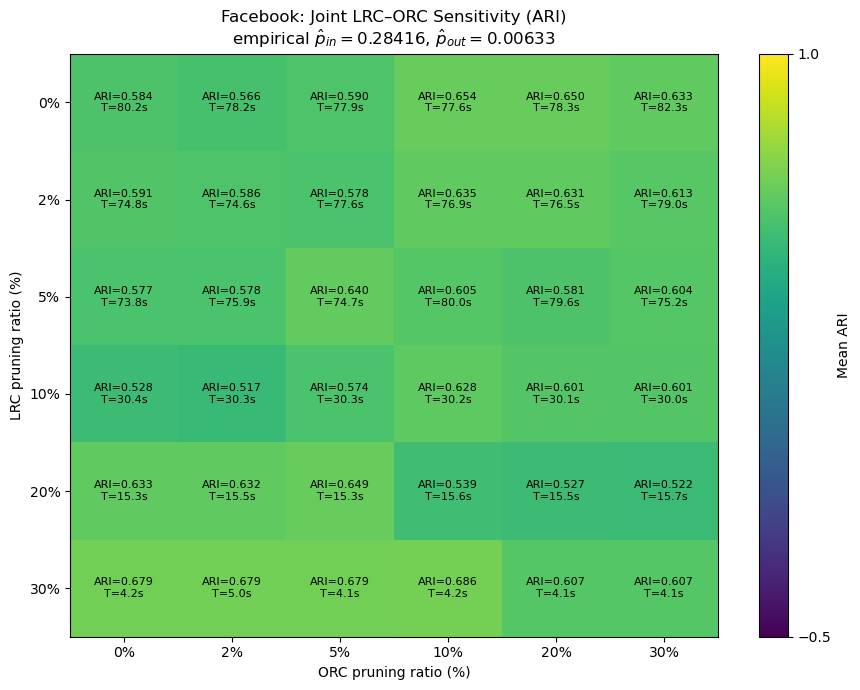

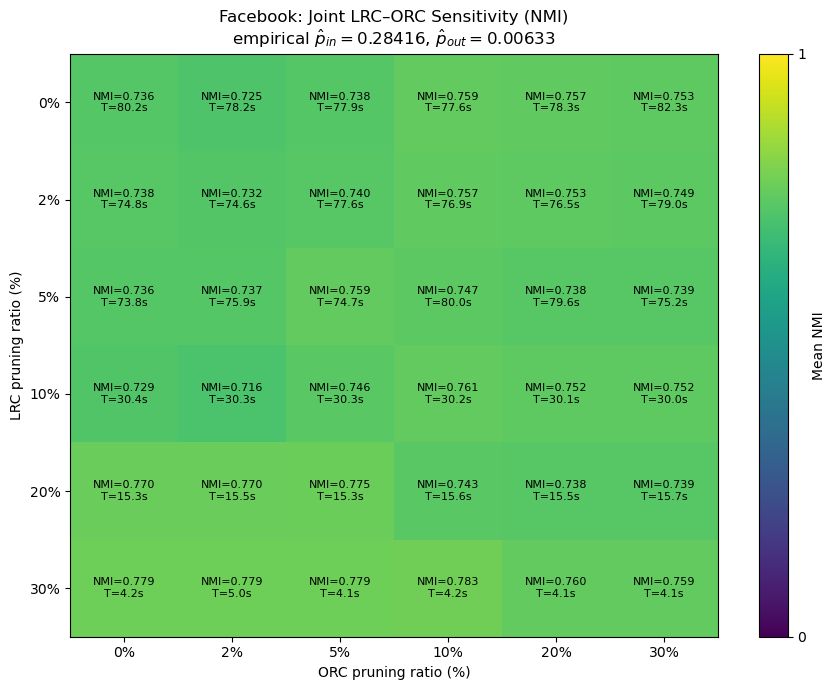


Saved:
  facebook_ari_lrc_orc_heatmap_with_runtime.png
  facebook_nmi_lrc_orc_heatmap_with_runtime.png
  facebook_lrc_orc_heatmap_summary.csv
  facebook_lrc_orc_heatmap_raw.csv
  facebook_empirical_pin_pout.csv


In [63]:
# ============================================================
# FACEBOOK: JOINT LRC-ORC PRUNING HEATMAPS
# Each cell shows accuracy + runtime
# p_in and p_out are estimated from the actual Facebook benchmark
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 0. OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR = Path(
    "./facebook_heatmaps"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 1. ESTIMATE EMPIRICAL p_in AND p_out
# ============================================================

def estimate_empirical_pin_pout(
    graph,
    label_attribute="label_gt",
):

    # --------------------------------------------------------
    # Keep nodes with an evaluation label
    # --------------------------------------------------------

    labeled_nodes = [
        node
        for node in graph.nodes()
        if label_attribute
        in graph.nodes[node]
    ]


    labels = {
        node:
            graph.nodes[node][
                label_attribute
            ]
        for node in labeled_nodes
    }


    # --------------------------------------------------------
    # Number of nodes in each ground-truth community
    # --------------------------------------------------------

    label_counts = (
        pd.Series(
            list(
                labels.values()
            )
        )
        .value_counts()
        .to_dict()
    )


    # --------------------------------------------------------
    # Possible within-community node pairs
    # --------------------------------------------------------

    possible_within = sum(
        n * (n - 1) / 2
        for n in label_counts.values()
    )


    total_nodes = len(
        labeled_nodes
    )


    possible_total = (
        total_nodes
        * (total_nodes - 1)
        / 2
    )


    possible_between = (
        possible_total
        - possible_within
    )


    # --------------------------------------------------------
    # Count observed within/between edges
    # --------------------------------------------------------

    observed_within = 0
    observed_between = 0


    labeled_set = set(
        labeled_nodes
    )


    for u, v in graph.edges():

        if (
            u not in labeled_set
            or v not in labeled_set
        ):
            continue


        if labels[u] == labels[v]:

            observed_within += 1

        else:

            observed_between += 1


    # --------------------------------------------------------
    # Empirical probabilities
    # --------------------------------------------------------

    p_in_hat = (
        observed_within
        / possible_within
        if possible_within > 0
        else np.nan
    )


    p_out_hat = (
        observed_between
        / possible_between
        if possible_between > 0
        else np.nan
    )


    return {

        "p_in":
            p_in_hat,

        "p_out":
            p_out_hat,

        "observed_within_edges":
            observed_within,

        "observed_between_edges":
            observed_between,

        "possible_within_pairs":
            possible_within,

        "possible_between_pairs":
            possible_between,

        "n_labeled":
            total_nodes,

        "n_labels":
            len(
                label_counts
            ),
    }


facebook_structure = (
    estimate_empirical_pin_pout(
        H,
        label_attribute="label_gt",
    )
)


FACEBOOK_PIN = (
    facebook_structure[
        "p_in"
    ]
)

FACEBOOK_POUT = (
    facebook_structure[
        "p_out"
    ]
)


print(
    "=" * 70
)

print(
    "FACEBOOK EMPIRICAL STRUCTURE"
)

print(
    "=" * 70
)


print(
    f"Nodes       : "
    f"{facebook_structure['n_labeled']}"
)

print(
    f"Labels      : "
    f"{facebook_structure['n_labels']}"
)

print(
    f"Within edges: "
    f"{facebook_structure['observed_within_edges']}"
)

print(
    f"Between edges: "
    f"{facebook_structure['observed_between_edges']}"
)

print(
    f"Estimated p_in  = "
    f"{FACEBOOK_PIN:.6f}"
)

print(
    f"Estimated p_out = "
    f"{FACEBOOK_POUT:.6f}"
)


# ============================================================
# 2. SENSITIVITY GRID
# ============================================================

# Includes the current 2% / 2% Facebook setting
LRC_HEAT_VALUES = [
    0,
    2,
    5,
    10,
    20,
    30,
]


ORC_HEAT_VALUES = [
    0,
    2,
    5,
    10,
    20,
    30,
]


HEATMAP_ALPHA = 0.5


HEATMAP_SEEDS = [
    0,
    1,
    4,
    42,
]


print(
    "\n"
    + "=" * 70
)

print(
    "FACEBOOK JOINT LRC-ORC SENSITIVITY"
)

print(
    "=" * 70
)

print(
    "LRC values:",
    LRC_HEAT_VALUES,
)

print(
    "ORC values:",
    ORC_HEAT_VALUES,
)

print(
    "alpha:",
    HEATMAP_ALPHA,
)

print(
    "seeds:",
    HEATMAP_SEEDS,
)


# ============================================================
# 3. RUN ALL PRUNING CONFIGURATIONS
# ============================================================

heatmap_rows = []


for lrc_pct in LRC_HEAT_VALUES:

    for orc_pct in ORC_HEAT_VALUES:

        print(
            f"\nRunning "
            f"LRC={lrc_pct}% | "
            f"ORC={orc_pct}% | "
            f"alpha={HEATMAP_ALPHA}"
        )


        # ----------------------------------------------------
        # Run curvature preprocessing once for this cell
        # ----------------------------------------------------

        try:

            combo_info_heat = (
                cdu.prepare_combo_graph(
                    graph=H,
                    lrc_pct=lrc_pct,
                    orc_pct=orc_pct,
                    alpha=HEATMAP_ALPHA,
                    iterations=ORC_ITERATIONS,
                    method="Sinkhorn",
                    weight="weight",
                )
            )


        except Exception as error:

            print(
                "Preparation failed:",
                repr(error),
            )


            for seed in HEATMAP_SEEDS:

                heatmap_rows.append(
                    {
                        "seed":
                            seed,

                        "lrc_pct":
                            lrc_pct,

                        "orc_pct":
                            orc_pct,

                        "alpha":
                            HEATMAP_ALPHA,

                        "p_in":
                            FACEBOOK_PIN,

                        "p_out":
                            FACEBOOK_POUT,

                        "ARI":
                            np.nan,

                        "NMI":
                            np.nan,

                        "Runtime":
                            np.nan,

                        "Prep_time":
                            np.nan,

                        "Community_time":
                            np.nan,

                        "V":
                            np.nan,

                        "E":
                            np.nan,

                        "status":
                            "failed",
                    }
                )

            continue


        # ----------------------------------------------------
        # Evaluate Louvain for different random seeds
        # ----------------------------------------------------

        for seed in HEATMAP_SEEDS:

            result = (
                cdu.evaluate_prepared_graph(
                    info=combo_info_heat,
                    algorithm="louvain",
                    seed=seed,
                    weight="weight",
                    label_attribute="label_gt",
                )
            )


            heatmap_rows.append(
                {
                    "seed":
                        seed,

                    "lrc_pct":
                        lrc_pct,

                    "orc_pct":
                        orc_pct,

                    "alpha":
                        HEATMAP_ALPHA,

                    "p_in":
                        FACEBOOK_PIN,

                    "p_out":
                        FACEBOOK_POUT,

                    "ARI":
                        result[
                            "ARI"
                        ],

                    "NMI":
                        result[
                            "NMI"
                        ],

                    "Runtime":
                        result[
                            "runtime_sec"
                        ],

                    "Prep_time":
                        result[
                            "prep_time"
                        ],

                    "Community_time":
                        result[
                            "community_time"
                        ],

                    "V":
                        result[
                            "V"
                        ],

                    "E":
                        result[
                            "E"
                        ],

                    "status":
                        "ok",
                }
            )


df_facebook_heatmap_raw = (
    pd.DataFrame(
        heatmap_rows
    )
)


# ============================================================
# 4. MEAN ± STD ACROSS SEEDS
# ============================================================

df_facebook_heatmap_valid = (
    df_facebook_heatmap_raw[
        df_facebook_heatmap_raw[
            "status"
        ] == "ok"
    ]
    .copy()
)


facebook_heatmap_summary = (
    df_facebook_heatmap_valid
    .groupby(
        [
            "lrc_pct",
            "orc_pct",
        ],
        as_index=False,
    )
    .agg(

        ARI_mean=(
            "ARI",
            "mean",
        ),

        ARI_std=(
            "ARI",
            "std",
        ),

        NMI_mean=(
            "NMI",
            "mean",
        ),

        NMI_std=(
            "NMI",
            "std",
        ),

        Runtime_mean=(
            "Runtime",
            "mean",
        ),

        Runtime_std=(
            "Runtime",
            "std",
        ),

        Prep_time_mean=(
            "Prep_time",
            "mean",
        ),

        Community_time_mean=(
            "Community_time",
            "mean",
        ),

        V_mean=(
            "V",
            "mean",
        ),

        E_mean=(
            "E",
            "mean",
        ),
    )
)


print(
    "\nFacebook joint sensitivity summary:"
)

display(
    facebook_heatmap_summary
)


# ============================================================
# 5. CONVERT SUMMARY TO HEATMAP MATRICES
# ============================================================

def make_heatmap_matrix(
    dataframe,
    value_column,
):

    return (
        dataframe
        .pivot(
            index="lrc_pct",
            columns="orc_pct",
            values=value_column,
        )
        .reindex(
            index=LRC_HEAT_VALUES,
            columns=ORC_HEAT_VALUES,
        )
    )


ari_matrix = (
    make_heatmap_matrix(
        facebook_heatmap_summary,
        "ARI_mean",
    )
)


nmi_matrix = (
    make_heatmap_matrix(
        facebook_heatmap_summary,
        "NMI_mean",
    )
)


runtime_matrix = (
    make_heatmap_matrix(
        facebook_heatmap_summary,
        "Runtime_mean",
    )
)


# ============================================================
# 6. HEATMAP PLOTTING FUNCTION
#
# COLOR = accuracy
# TEXT  = accuracy + runtime
# ============================================================

def plot_facebook_metric_heatmap(
    metric_matrix,
    runtime_matrix,
    metric_name,
):

    fig, ax = plt.subplots(
        figsize=(9, 7)
    )


    # --------------------------------------------------------
    # Metric-specific color scale
    # ARI: -0.5 to 1
    # NMI:  0 to 1
    # --------------------------------------------------------

    if metric_name == "ARI":

        vmin = -0.5
        vmax = 1.0

        colorbar_ticks = [
            -0.5,
            1.0,
        ]

    elif metric_name == "NMI":

        vmin = 0.0
        vmax = 1.0

        colorbar_ticks = [
            0.0,
            1.0,
        ]

    else:

        vmin = None
        vmax = None
        colorbar_ticks = None


    # --------------------------------------------------------
    # Heatmap
    # --------------------------------------------------------

    im = ax.imshow(
        metric_matrix.values,
        vmin=vmin,
        vmax=vmax,
        aspect="auto",
    )


    # --------------------------------------------------------
    # ORC pruning on horizontal axis
    # --------------------------------------------------------

    ax.set_xticks(
        np.arange(
            len(
                ORC_HEAT_VALUES
            )
        )
    )


    ax.set_xticklabels(
        [
            f"{value}%"
            for value
            in ORC_HEAT_VALUES
        ]
    )


    # --------------------------------------------------------
    # LRC pruning on vertical axis
    # --------------------------------------------------------

    ax.set_yticks(
        np.arange(
            len(
                LRC_HEAT_VALUES
            )
        )
    )


    ax.set_yticklabels(
        [
            f"{value}%"
            for value
            in LRC_HEAT_VALUES
        ]
    )


    ax.set_xlabel(
        "ORC pruning ratio (%)"
    )


    ax.set_ylabel(
        "LRC pruning ratio (%)"
    )


    ax.set_title(
        f"Facebook: Joint LRC–ORC Sensitivity ({metric_name})\n"
        f"empirical "
        f"$\\hat{{p}}_{{in}}={FACEBOOK_PIN:.5f}$, "
        f"$\\hat{{p}}_{{out}}={FACEBOOK_POUT:.5f}$"
    )


    # --------------------------------------------------------
    # Cell annotations
    # --------------------------------------------------------

    for i, lrc_pct in enumerate(
        LRC_HEAT_VALUES
    ):

        for j, orc_pct in enumerate(
            ORC_HEAT_VALUES
        ):


            metric_value = (
                metric_matrix.loc[
                    lrc_pct,
                    orc_pct
                ]
            )


            runtime_value = (
                runtime_matrix.loc[
                    lrc_pct,
                    orc_pct
                ]
            )


            if (
                pd.isna(
                    metric_value
                )
                or pd.isna(
                    runtime_value
                )
            ):

                text = "failed"


            else:

                text = (
                    f"{metric_name}="
                    f"{metric_value:.3f}\n"
                    f"T="
                    f"{runtime_value:.1f}s"
                )


            ax.text(
                j,
                i,
                text,
                ha="center",
                va="center",
                fontsize=8,
            )


    # --------------------------------------------------------
    # Colorbar
    # --------------------------------------------------------

    cbar = fig.colorbar(
        im,
        ax=ax,
    )


    if colorbar_ticks is not None:

        cbar.set_ticks(
            colorbar_ticks
        )


    cbar.set_label(
        f"Mean {metric_name}"
    )


    fig.tight_layout()

    return fig


# ============================================================
# 7. ARI HEATMAP
# ============================================================

fig_ari = (
    plot_facebook_metric_heatmap(
        metric_matrix=
            ari_matrix,

        runtime_matrix=
            runtime_matrix,

        metric_name=
            "ARI",
    )
)


plt.show()


# ============================================================
# 8. NMI HEATMAP
# ============================================================

fig_nmi = (
    plot_facebook_metric_heatmap(
        metric_matrix=
            nmi_matrix,

        runtime_matrix=
            runtime_matrix,

        metric_name=
            "NMI",
    )
)


plt.show()


# ============================================================
# 9. SAVE FIGURES AND CSV FILES
# ============================================================

fig_ari.savefig(
    OUTPUT_DIR
    / "facebook_ari_lrc_orc_heatmap_with_runtime.png",
    dpi=300,
    bbox_inches="tight",
)


fig_nmi.savefig(
    OUTPUT_DIR
    / "facebook_nmi_lrc_orc_heatmap_with_runtime.png",
    dpi=300,
    bbox_inches="tight",
)


facebook_heatmap_summary.to_csv(
    OUTPUT_DIR
    / "facebook_lrc_orc_heatmap_summary.csv",
    index=False,
)


df_facebook_heatmap_raw.to_csv(
    OUTPUT_DIR
    / "facebook_lrc_orc_heatmap_raw.csv",
    index=False,
)


pd.DataFrame(
    [facebook_structure]
).to_csv(
    OUTPUT_DIR
    / "facebook_empirical_pin_pout.csv",
    index=False,
)


plt.close(
    fig_ari
)

plt.close(
    fig_nmi
)


print(
    "\nSaved:"
)

print(
    "  facebook_ari_lrc_orc_heatmap_with_runtime.png"
)

print(
    "  facebook_nmi_lrc_orc_heatmap_with_runtime.png"
)

print(
    "  facebook_lrc_orc_heatmap_summary.csv"
)

print(
    "  facebook_lrc_orc_heatmap_raw.csv"
)

print(
    "  facebook_empirical_pin_pout.csv"
)


Facebook
empirical p_in  = 0.284161
empirical p_out = 0.006329

Facebook | LRC=0% | ORC=0%
seed=0 | ARI=0.584 | NMI=0.736 | T=79.06s
seed=1 | ARI=0.584 | NMI=0.736 | T=79.06s

Facebook | LRC=0% | ORC=5%
seed=0 | ARI=0.603 | NMI=0.745 | T=77.65s
seed=1 | ARI=0.548 | NMI=0.722 | T=77.65s

Facebook | LRC=0% | ORC=10%
seed=0 | ARI=0.654 | NMI=0.759 | T=77.27s
seed=1 | ARI=0.654 | NMI=0.759 | T=77.27s

Facebook | LRC=0% | ORC=20%
seed=0 | ARI=0.650 | NMI=0.757 | T=78.20s
seed=1 | ARI=0.650 | NMI=0.757 | T=78.20s

Facebook | LRC=0% | ORC=30%
seed=0 | ARI=0.633 | NMI=0.753 | T=85.11s
seed=1 | ARI=0.633 | NMI=0.753 | T=85.11s

Facebook | LRC=5% | ORC=0%
seed=0 | ARI=0.578 | NMI=0.737 | T=74.80s
seed=1 | ARI=0.577 | NMI=0.736 | T=74.80s

Facebook | LRC=5% | ORC=5%
seed=0 | ARI=0.637 | NMI=0.757 | T=78.72s
seed=1 | ARI=0.641 | NMI=0.761 | T=78.72s

Facebook | LRC=5% | ORC=10%
seed=0 | ARI=0.605 | NMI=0.747 | T=74.43s
seed=1 | ARI=0.605 | NMI=0.747 | T=74.43s

Facebook | LRC=5% | ORC=20%
seed=0 

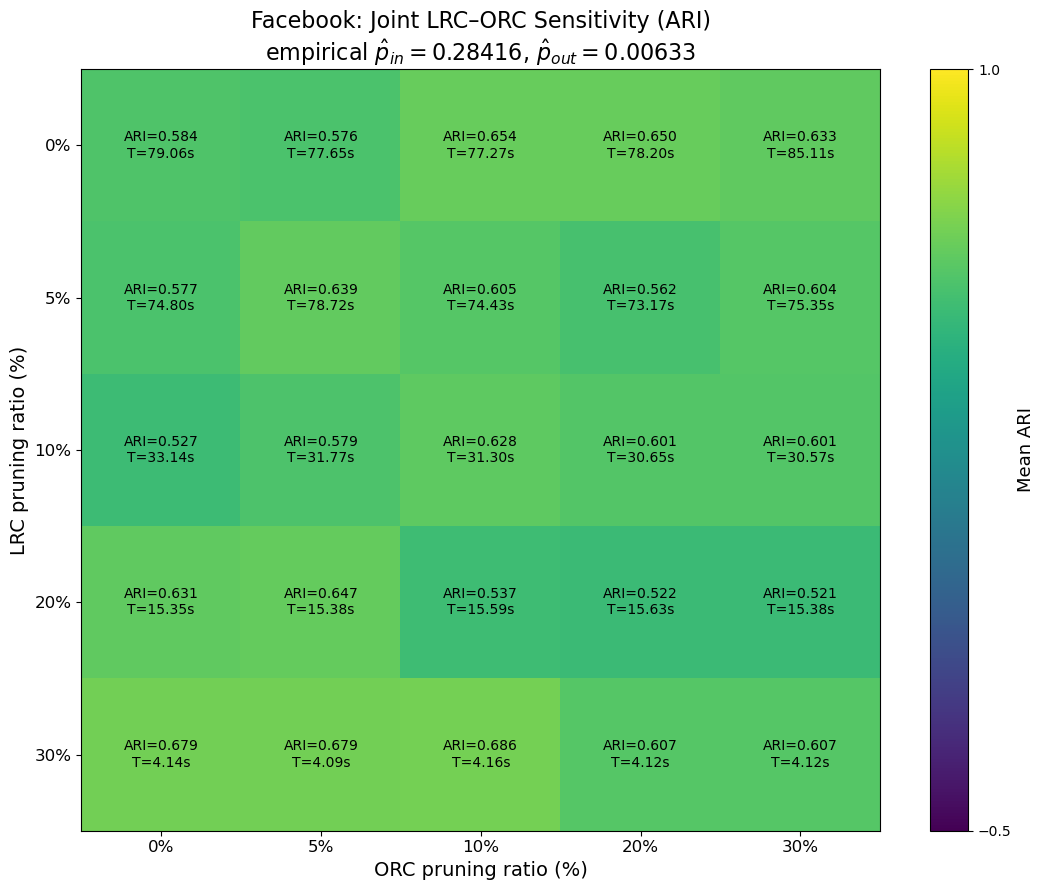

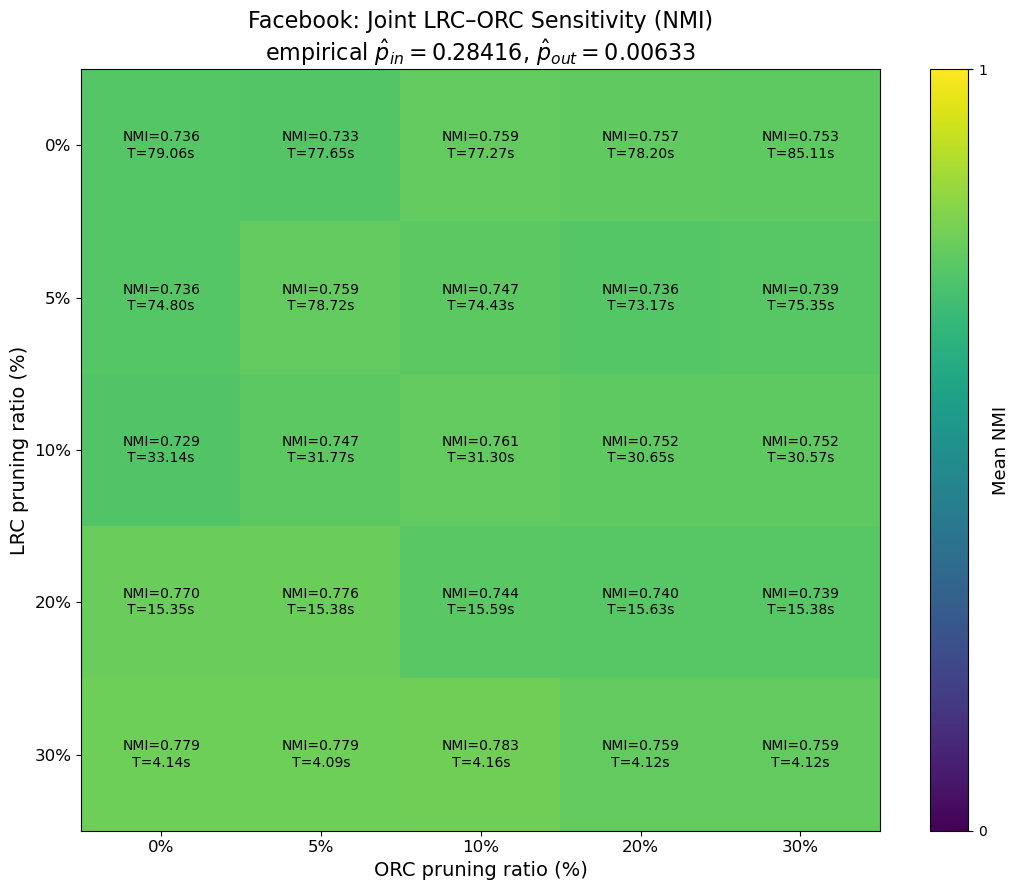

In [64]:
facebook_raw, facebook_summary = cdu.run_real_dataset_heatmap(
    H,
    "Facebook",
    orc_iterations=5
)

In [65]:
# ============================================================
# FACEBOOK — BUILD BENCHMARK FROM SCRATCH + CONDUCTANCE
# No dependency on previous notebook variables or custom utils
# ============================================================

import os
import gzip
import tarfile
import urllib.request
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import networkx as nx


# ============================================================
# 1. SETTINGS
# ============================================================

RANDOM_SEED = 42

MIN_CIRCLE_SIZE = 10
N_RANDOM_CIRCLES = 50

DATA_DIR = Path("./facebook_conductance_check")
DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

COMBINED_FILE = (
    DATA_DIR
    / "facebook_combined.txt.gz"
)

TAR_FILE = (
    DATA_DIR
    / "facebook.tar.gz"
)

EXTRACT_DIR = (
    DATA_DIR
    / "facebook"
)

COMBINED_URL = (
    "https://snap.stanford.edu/data/"
    "facebook_combined.txt.gz"
)

TAR_URL = (
    "https://snap.stanford.edu/data/"
    "facebook.tar.gz"
)


# ============================================================
# 2. DOWNLOAD DATA
# ============================================================

if not COMBINED_FILE.exists():

    print(
        "Downloading facebook_combined.txt.gz..."
    )

    urllib.request.urlretrieve(
        COMBINED_URL,
        COMBINED_FILE
    )

else:

    print(
        "facebook_combined.txt.gz already exists."
    )


if not TAR_FILE.exists():

    print(
        "Downloading facebook.tar.gz..."
    )

    urllib.request.urlretrieve(
        TAR_URL,
        TAR_FILE
    )

else:

    print(
        "facebook.tar.gz already exists."
    )


# ============================================================
# 3. EXTRACT CIRCLE FILES
# ============================================================

if not EXTRACT_DIR.exists():

    print(
        "Extracting facebook.tar.gz..."
    )

    with tarfile.open(
        TAR_FILE,
        "r:gz"
    ) as tar:

        tar.extractall(
            DATA_DIR
        )

else:

    print(
        "Facebook files already extracted."
    )


# ============================================================
# 4. LOAD FACEBOOK COMBINED GRAPH
# ============================================================

G_full = nx.read_edgelist(
    COMBINED_FILE,
    nodetype=str
)

G_full.remove_edges_from(
    nx.selfloop_edges(
        G_full
    )
)


print("\nFULL FACEBOOK GRAPH")

print(
    "Nodes:",
    G_full.number_of_nodes()
)

print(
    "Edges:",
    G_full.number_of_edges()
)

print(
    "Connected components:",
    nx.number_connected_components(
        G_full
    )
)


# Expected:
# Nodes = 4039
# Edges = 88234


# ============================================================
# 5. LOAD ALL FACEBOOK CIRCLES
# ============================================================

communities = []


circle_files = sorted(
    EXTRACT_DIR.glob(
        "*.circles"
    )
)


print(
    "\nCircle files:",
    len(circle_files)
)


for circle_file in circle_files:

    ego_id = (
        circle_file
        .stem
    )

    with open(
        circle_file,
        "r"
    ) as file:

        for line in file:

            parts = (
                line.strip()
                .split()
            )

            if len(parts) < 2:
                continue

            circle_name = (
                parts[0]
                .rstrip(":")
            )

            nodes = parts[1:]

            communities.append(
                {
                    "ego_id": ego_id,
                    "circle_name": circle_name,
                    "nodes": set(nodes),
                    "size": len(nodes)
                }
            )


print(
    "Total circles:",
    len(communities)
)


# Expected:
# Total circles = 193


# ============================================================
# 6. FUNCTION FOR INITIAL CIRCLE CONDUCTANCE
# ============================================================

def community_conductance(
    G,
    nodes
):

    S = (
        set(nodes)
        & set(G.nodes())
    )

    if len(S) == 0:
        return np.nan

    S_bar = (
        set(G.nodes())
        - S
    )

    cut = nx.cut_size(
        G,
        S,
        S_bar
    )

    vol_S = sum(
        dict(
            G.degree(S)
        ).values()
    )

    vol_bar = sum(
        dict(
            G.degree(S_bar)
        ).values()
    )

    denominator = min(
        vol_S,
        vol_bar
    )

    if denominator == 0:
        return np.nan

    return (
        cut
        / denominator
    )


# ============================================================
# 7. FIND ELIGIBLE CIRCLES
# ============================================================

rows = []


for cid, community in enumerate(
    communities
):

    if (
        community["size"]
        < MIN_CIRCLE_SIZE
    ):
        continue

    conductance = (
        community_conductance(
            G_full,
            community["nodes"]
        )
    )

    if not np.isfinite(
        conductance
    ):
        continue

    rows.append(
        {
            "community_id": cid,
            "ego_id": (
                community[
                    "ego_id"
                ]
            ),
            "circle_name": (
                community[
                    "circle_name"
                ]
            ),
            "size": (
                community[
                    "size"
                ]
            ),
            "conductance": (
                conductance
            )
        }
    )


metric_df = pd.DataFrame(
    rows
)


print(
    "\nEligible circles:",
    len(metric_df)
)


# Expected:
# Eligible circles = 84


# ============================================================
# 8. RANDOMLY SELECT 50 CIRCLES
#    Same random seed as benchmark
# ============================================================

rng = np.random.default_rng(
    RANDOM_SEED
)


number_to_select = min(
    N_RANDOM_CIRCLES,
    len(metric_df)
)


picked_ids = (
    rng.choice(
        metric_df[
            "community_id"
        ].tolist(),
        size=number_to_select,
        replace=False
    )
    .tolist()
)


picked_ids = sorted(
    picked_ids
)


print(
    "Selected circles:",
    len(picked_ids)
)


# ============================================================
# 9. BUILD RAW BENCHMARK
# ============================================================

node_to_cids = defaultdict(
    list
)


for cid in picked_ids:

    for node in (
        communities[cid][
            "nodes"
        ]
    ):

        if node in G_full:

            node_to_cids[
                node
            ].append(
                cid
            )


nodes_of_interest = set(
    node_to_cids.keys()
)


G_raw = G_full.subgraph(
    nodes_of_interest
).copy()


print(
    "\nBefore GCC:"
)

print(
    "Nodes:",
    G_raw.number_of_nodes()
)

print(
    "Edges:",
    G_raw.number_of_edges()
)

print(
    "Components:",
    nx.number_connected_components(
        G_raw
    )
)


# Expected approximately:
# Nodes = 1980
# Edges = 43877
# Components = 29


# ============================================================
# 10. RETAIN GIANT CONNECTED COMPONENT
# ============================================================

largest_component = max(
    nx.connected_components(
        G_raw
    ),
    key=len
)


H = G_raw.subgraph(
    largest_component
).copy()


print(
    "\nAfter GCC:"
)

print(
    "Nodes:",
    H.number_of_nodes()
)

print(
    "Edges:",
    H.number_of_edges()
)

print(
    "Components:",
    nx.number_connected_components(
        H
    )
)


# IMPORTANT CHECK:
# Expected:
# Nodes = 1771
# Edges = 42220


# ============================================================
# 11. ASSIGN ONE GROUND-TRUTH LABEL
#     TO EACH NODE
#
# For overlapping nodes:
# choose the smallest selected circle.
# ============================================================

cid_to_label = {
    cid: label
    for label, cid
    in enumerate(
        picked_ids
    )
}


community_size = {
    cid: communities[
        cid
    ][
        "size"
    ]
    for cid
    in picked_ids
}


for node in H.nodes():

    node_cids = (
        node_to_cids.get(
            node,
            []
        )
    )

    if len(
        node_cids
    ) == 0:

        continue


    best_cid = min(
        node_cids,
        key=lambda cid:
        community_size[cid]
    )


    H.nodes[node][
        "label_gt"
    ] = cid_to_label[
        best_cid
    ]


    H.nodes[node][
        "original_cids"
    ] = node_cids


    H.nodes[node][
        "is_overlap"
    ] = int(
        len(node_cids) > 1
    )


# ============================================================
# 12. FINAL LABEL CHECK
# ============================================================

EVAL_NODES = [
    node
    for node
    in H.nodes()
    if "label_gt"
    in H.nodes[node]
]


unique_labels = sorted({
    H.nodes[node][
        "label_gt"
    ]
    for node
    in EVAL_NODES
})


print(
    "\nFINAL FACEBOOK BENCHMARK"
)

print(
    "Nodes:",
    H.number_of_nodes()
)

print(
    "Edges:",
    H.number_of_edges()
)

print(
    "Labeled nodes:",
    len(EVAL_NODES)
)

print(
    "Number of labels:",
    len(unique_labels)
)


# Expected:
# Nodes = 1771
# Edges = 42220
# Labels = 39


# ============================================================
# 13. FINAL CONDUCTANCE
# ============================================================

rows = []

all_nodes = set(
    H.nodes()
)


for label in unique_labels:

    S = {
        node
        for node
        in H.nodes()
        if H.nodes[node].get(
            "label_gt"
        ) == label
    }

    S_bar = (
        all_nodes - S
    )


    cut = nx.cut_size(
        H,
        S,
        S_bar
    )


    vol_S = sum(
        dict(
            H.degree(S)
        ).values()
    )


    vol_bar = sum(
        dict(
            H.degree(S_bar)
        ).values()
    )


    # --------------------------------------------------------
    # Definition used in the PAPER:
    #
    # cut(S,Sbar) /
    # min(vol(S), vol(Sbar))
    # --------------------------------------------------------

    denominator_paper = min(
        vol_S,
        vol_bar
    )


    conductance_paper = (
        cut / denominator_paper
        if denominator_paper > 0
        else np.nan
    )


    # --------------------------------------------------------
    # Also calculate cut / vol(S)
    # so we can diagnose any difference with older code.
    # --------------------------------------------------------

    conductance_volS = (
        cut / vol_S
        if vol_S > 0
        else np.nan
    )


    rows.append(
        {
            "label": label,
            "size": len(S),
            "cut": cut,
            "vol_S": vol_S,
            "vol_S_bar": vol_bar,
            "conductance_paper":
                conductance_paper,
            "conductance_cut_over_volS":
                conductance_volS,
        }
    )


conductance_df = pd.DataFrame(
    rows
)


print(
    "\nCONDUCTANCE BY COMMUNITY"
)

display(
    conductance_df
)


# ============================================================
# 14. FINAL MEANS
# ============================================================

mean_conductance_paper = (
    conductance_df[
        "conductance_paper"
    ].mean()
)


mean_conductance_volS = (
    conductance_df[
        "conductance_cut_over_volS"
    ].mean()
)


print(
    "\n=========================================="
)

print(
    "FACEBOOK — PAPER DEFINITION"
)

print(
    "Mean Conductance =",
    mean_conductance_paper
)

print(
    "Rounded to 4 decimals =",
    round(
        mean_conductance_paper,
        4
    )
)

print(
    "\nAlternative cut/vol(S) mean =",
    mean_conductance_volS
)

print(
    "Alternative rounded =",
    round(
        mean_conductance_volS,
        4
    )
)

print(
    "=========================================="
)

facebook_combined.txt.gz already exists.
facebook.tar.gz already exists.
Facebook files already extracted.

FULL FACEBOOK GRAPH
Nodes: 4039
Edges: 88234
Connected components: 1

Circle files: 10
Total circles: 193

Eligible circles: 84
Selected circles: 50

Before GCC:
Nodes: 1980
Edges: 43877
Components: 29

After GCC:
Nodes: 1771
Edges: 42220
Components: 1

FINAL FACEBOOK BENCHMARK
Nodes: 1771
Edges: 42220
Labeled nodes: 1771
Number of labels: 39

CONDUCTANCE BY COMMUNITY


,label,size,cut,vol_S,vol_S_bar,conductance_paper,conductance_cut_over_volS
0,0,6,32,32,84408,1.000000,1.000000
1,1,26,391,549,83891,0.712204,0.712204
2,2,107,543,2209,82231,0.245813,0.245813
3,3,30,146,366,84074,0.398907,0.398907
4,4,10,24,78,84362,0.307692,0.307692
5,5,19,91,145,84295,0.627586,0.627586
6,6,10,19,59,84381,0.322034,0.322034
7,7,296,988,17956,66484,0.055023,0.055023
8,8,35,53,953,83487,0.055614,0.055614
9,9,29,91,147,84293,0.619048,0.619048



FACEBOOK — PAPER DEFINITION
Mean Conductance = 0.49444698838573614
Rounded to 4 decimals = 0.4944

Alternative cut/vol(S) mean = 0.49444698838573614
Alternative rounded = 0.4944


In [66]:
# ============================================================
# DIAGNOSTIC CHECK:
# Does LRC pruning disconnect the graph before Ricci flow?
# ============================================================

print("=" * 70)
print("COMBO CONNECTIVITY DIAGNOSTIC")
print("=" * 70)

# Start from original benchmark graph
graph_lrc = H.copy()

# Compute LRC
cdu.compute_LRC(
    graph_lrc,
    attribute="LRC"
)

# Apply combo-stage LRC pruning
after_lrc, cutoff_lrc, removed_lrc = cdu.prune_by_percentile(
    graph_lrc,
    attr="LRC",
    pct=LRC_COMBO_PCT
)

print("\n1. ORIGINAL GRAPH")
print("Nodes:", H.number_of_nodes())
print("Edges:", H.number_of_edges())
print("Components:", nx.number_connected_components(H))
print("Connected?:", nx.is_connected(H))

print("\n2. AFTER LRC PRUNING")
print("Nodes:", after_lrc.number_of_nodes())
print("Edges:", after_lrc.number_of_edges())
print("Removed LRC edges:", removed_lrc)
print("Components:", nx.number_connected_components(after_lrc))
print("Connected?:", nx.is_connected(after_lrc))

# Size of largest connected component after LRC
largest_cc_nodes = max(
    nx.connected_components(after_lrc),
    key=len
)

largest_cc = after_lrc.subgraph(
    largest_cc_nodes
).copy()

print("\n3. LARGEST CONNECTED COMPONENT AFTER LRC")
print("Nodes:", largest_cc.number_of_nodes())
print("Edges:", largest_cc.number_of_edges())

# Run Ricci flow
flow_graph = cdu.run_orc_flow_gcc(
    after_lrc,
    alpha=ALPHA,
    iterations=ORC_ITERATIONS,
    method="Sinkhorn"
)

print("\n4. AFTER RICCI FLOW — BEFORE ORC PRUNING")
print("Nodes:", flow_graph.number_of_nodes())
print("Edges:", flow_graph.number_of_edges())
print("Components:", nx.number_connected_components(flow_graph))
print("Connected?:", nx.is_connected(flow_graph))

# ORC pruning
after_orc, cutoff_orc, removed_orc = cdu.prune_by_percentile(
    flow_graph,
    attr="ricciCurvature",
    pct=ORC_COMBO_PCT
)

print("\n5. AFTER ORC PRUNING")
print("Nodes:", after_orc.number_of_nodes())
print("Edges:", after_orc.number_of_edges())
print("Removed ORC edges:", removed_orc)
print("Components:", nx.number_connected_components(after_orc))

print("\n6. TOTAL EDGE REDUCTION")
edge_reduction = (
    100
    * (
        1
        - after_orc.number_of_edges()
        / H.number_of_edges()
    )
)

print(f"Edge reduction: {edge_reduction:.4f}%")

# Check whether Ricci flow effectively selected the GCC
same_as_largest_cc = (
    flow_graph.number_of_nodes() == largest_cc.number_of_nodes()
    and
    flow_graph.number_of_edges() == largest_cc.number_of_edges()
)

print("\n7. DID RICCI FLOW EFFECTIVELY RETAIN ONLY THE GCC?")
print(same_as_largest_cc)

print("\n" + "=" * 70)

COMBO CONNECTIVITY DIAGNOSTIC

1. ORIGINAL GRAPH
Nodes: 1771
Edges: 42220
Components: 1
Connected?: True

2. AFTER LRC PRUNING
Nodes: 1771
Edges: 41164
Removed LRC edges: 1056
Components: 2
Connected?: False

3. LARGEST CONNECTED COMPONENT AFTER LRC
Nodes: 1755
Edges: 41065

4. AFTER RICCI FLOW — BEFORE ORC PRUNING
Nodes: 1755
Edges: 41065
Components: 1
Connected?: True

5. AFTER ORC PRUNING
Nodes: 1754
Edges: 40038
Removed ORC edges: 1027
Components: 4

6. TOTAL EDGE REDUCTION
Edge reduction: 5.1682%

7. DID RICCI FLOW EFFECTIVELY RETAIN ONLY THE GCC?
True

